<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:20px; font-weight:700;">MACHINE LEARNING IN DATA SCIENCE — LAB 02</div>
<div style="font-style:italic;">Building and Training Neural Networks with Scikit-Learn &amp; PyTorch</div>
<br>
<b>Student Name:</b> Phạm Tiến Triển<br>
<b>Student RollNumber:</b> SE182026
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">Prerequisites &amp; Setup</div>
Kiểm tra môi trường: các thư viện cần thiết, phiên bản PyTorch và GPU (CUDA).
</div>

In [5]:
# Run this cell to verify your environment
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report

print('PyTorch version:', torch.__version__)
print('CUDA available: ', torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
CUDA available:  True


<hr>
<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:18px; font-weight:700;">PART 1 — Regression MLP (30 pts)</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">1.1 Data Preparation [5 pts]</div>
Load bộ dữ liệu California Housing, chia train/test theo tỉ lệ 80/20 (<code>random_state=42</code>), sau đó chuẩn hóa bằng <code>StandardScaler</code>: chỉ <i>fit</i> trên tập train rồi <i>transform</i> cả hai tập để tránh rò rỉ thông tin của tập test vào mô hình.
</div>

In [12]:
# 1.1 Data Preparation
import pandas as pd

# Load dữ liệu
housing = fetch_california_housing()
X, y = housing.data, housing.target

print("Feature names:", housing.feature_names)
print("Target       :", housing.target_names, "(giá nhà trung vị, đơn vị 100.000 USD)")
print("Toàn bộ dữ liệu:", X.shape)

# Chia train/test 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Chuẩn hóa: fit trên train, transform cả train và test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nShape sau khi chia:")
print(f"  X_train: {X_train_scaled.shape} | y_train: {y_train.shape}")
print(f"  X_test : {X_test_scaled.shape} | y_test : {y_test.shape}")

# Kiểm tra nhanh: sau chuẩn hóa, tập train có mean ≈ 0 và std ≈ 1
print("\nMean (train, scaled):", X_train_scaled.mean(axis=0).round(3))
print("Std  (train, scaled):", X_train_scaled.std(axis=0).round(3))

# Xem 5 dòng đầu của dữ liệu gốc
pd.DataFrame(X, columns=housing.feature_names).assign(MedHouseVal=y).head()

Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target       : ['MedHouseVal'] (giá nhà trung vị, đơn vị 100.000 USD)
Toàn bộ dữ liệu: (20640, 8)

Shape sau khi chia:
  X_train: (16512, 8) | y_train: (16512,)
  X_test : (4128, 8) | y_test : (4128,)

Mean (train, scaled): [-0. -0.  0. -0. -0. -0.  0. -0.]
Std  (train, scaled): [1. 1. 1. 1. 1. 1. 1. 1.]


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">1.2 Baseline MLP Regressor [10 pts]</div>
MLP với 1 lớp ẩn 64 neuron, hàm kích hoạt ReLU, optimizer Adam, <code>max_iter=500</code>. Đánh giá trên tập test bằng RMSE và R², sau đó vẽ learning curve (loss theo từng iteration) từ <code>loss_curve_</code>.
</div>

In [13]:
# 1.2 Baseline MLP Regressor
import time
from sklearn.metrics import r2_score

baseline = MLPRegressor(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42,
)

start = time.time()
baseline.fit(X_train_scaled, y_train)
train_time = time.time() - start

y_pred_base = baseline.predict(X_test_scaled)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
r2_base = r2_score(y_test, y_pred_base)

print(f"Số iteration đã chạy : {baseline.n_iter_} / {baseline.max_iter}")
print(f"Loss cuối cùng (train): {baseline.loss_:.4f}")
print(f"Thời gian huấn luyện : {train_time:.1f} s")
print(f"\nTest RMSE: {rmse_base:.4f}")
print(f"Test R²  : {r2_base:.4f}")

Số iteration đã chạy : 220 / 500
Loss cuối cùng (train): 0.1402
Thời gian huấn luyện : 9.4 s

Test RMSE: 0.5428
Test R²  : 0.7752


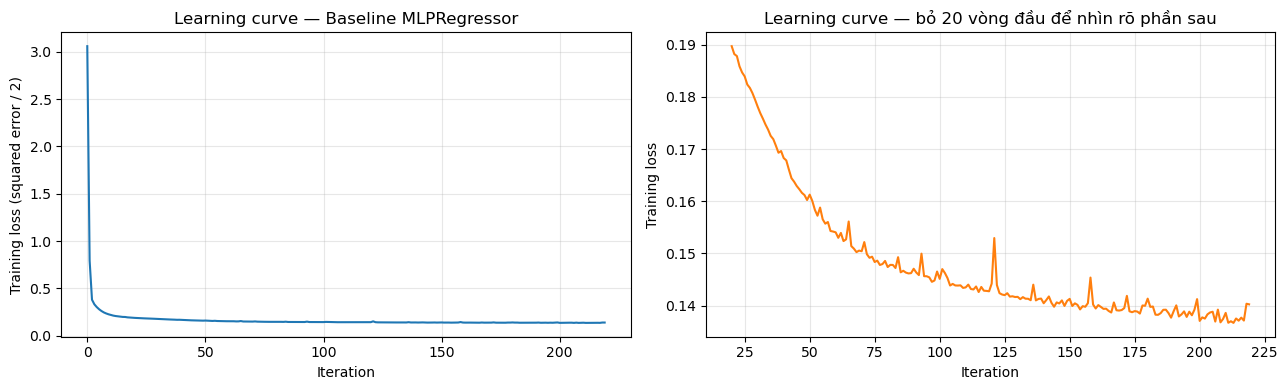

In [10]:
# Learning curve: loss theo từng iteration
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(baseline.loss_curve_, color="tab:blue")
axes[0].set_title("Learning curve — Baseline MLPRegressor")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Training loss (squared error / 2)")
axes[0].grid(alpha=0.3)

# Bỏ 20 vòng đầu (đoạn lao dốc) để trục dọc nhỏ lại, nhìn rõ phần giảm chậm và đi ngang
start_it = 20
axes[1].plot(range(start_it, len(baseline.loss_curve_)), baseline.loss_curve_[start_it:], color="tab:orange")
axes[1].set_title(f"Learning curve — bỏ {start_it} vòng đầu để nhìn rõ phần sau")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training loss")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — Mô hình đã học xong chưa?</b>
<ul>
<li><b>Mô hình đoán giá nhà tốt đến đâu:</b> trên những căn nhà mô hình chưa từng thấy, mỗi lần đoán giá lệch trung bình khoảng <b>54.000 USD</b> (RMSE = 0.543). Mô hình giải thích được khoảng <b>77,5%</b> lý do vì sao nhà này đắt, nhà kia rẻ (R² = 0.775). Phần còn lại đến từ những yếu tố mà dữ liệu không có.</li>
<li><b>Biểu đồ cho thấy gì:</b> mỗi điểm trên biểu đồ là một vòng học, tức mô hình xem hết toàn bộ dữ liệu một lần. Trong khoảng 5 vòng đầu, số lỗi giảm rất nhanh (từ khoảng 3.0 xuống 0.4), vì lúc đầu mô hình gần như đoán bừa nên chỉ cần học được vài quy luật chính là tiến bộ rõ rệt. Sau đó số lỗi giảm rất chậm rồi gần như đứng yên ở khoảng 0.14.</li>
<li><b>Mô hình đã học xong:</b> mô hình tự dừng ở vòng thứ <b>220</b>, dù được phép học tới 500 vòng. Lý do là trong 10 vòng liên tiếp, số lỗi gần như không giảm thêm nữa. Đoạn đường nằm ngang trên biểu đồ cho thấy với kích thước hiện tại (1 lớp, 64 neuron), mô hình đã học hết mức có thể; cho học thêm cũng không giỏi hơn.</li>
<li><b>Vì sao đường lỗi có những chỗ nhô lên:</b> mô hình không học hết 16.512 căn nhà rồi mới sửa một lần. Nó chia dữ liệu thành từng nhóm nhỏ, mỗi nhóm 200 căn, học xong nhóm nào thì sửa ngay theo nhóm đó. Nếu trong một vòng, mô hình gặp nhiều nhóm có những căn nhà "lạ" (ví dụ giá cao hoặc thấp bất thường), nó sẽ sửa theo những căn lạ này và đoán các căn bình thường kém đi một chút, nên số lỗi của vòng đó tăng lên (như ở vòng 120). Sang vòng sau, mô hình sửa lại và số lỗi giảm về như cũ. Vì vậy các chỗ nhô lên chỉ là tạm thời; nhìn tổng thể, đường lỗi vẫn đi xuống.</li>
<li><b>Mô hình hiểu bài, không học vẹt:</b> trên dữ liệu đã học, mô hình đoán lệch khoảng 53.000 USD; trên dữ liệu mới, lệch khoảng 54.000 USD. Hai con số gần như bằng nhau, nghĩa là mô hình thật sự hiểu quy luật chứ không chỉ nhớ đáp án. Muốn đoán chính xác hơn thì cần một mô hình lớn hơn hoặc cách cài đặt khác.</li>
</ul>
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">1.3 Hyperparameter Tuning [15 pts]</div>
Dùng <code>GridSearchCV</code> để thử tất cả 24 tổ hợp siêu tham số (số lớp ẩn (3), hàm kích hoạt (2), learning rate(2), alpha(2)), mỗi tổ hợp đánh giá bằng 5-fold cross-validation với thước đo RMSE. Chạy song song trên tất cả nhân CPU (<code>n_jobs=-1</code>), mất khoảng 5–8 phút.
</div>

In [14]:
# 1.3 Hyperparameter Tuning với GridSearchCV
import warnings
from sklearn.exceptions import ConvergenceWarning

param_grid = {
    "hidden_layer_sizes": [(64,), (128, 64), (256, 128, 64)],
    "activation": ["relu", "tanh"],
    "learning_rate_init": [0.01, 0.001],
    "alpha": [0.0001, 0.001],  # L2 regularisation
}

grid = GridSearchCV(
    estimator=MLPRegressor(solver="adam", max_iter=500, random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
)

start = time.time()
# Chỉ ẩn cảnh báo "chưa hội tụ". resetwarnings() xoá các bộ lọc cảnh báo của Jupyter,
# để các tiến trình chạy song song không phải nạp IPython (tránh lỗi MemoryError).
with warnings.catch_warnings():
    warnings.resetwarnings()
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    grid.fit(X_train_scaled, y_train)
grid_time = time.time() - start

print(f"\nThời gian GridSearch: {grid_time/60:.1f} phút")
print("Best parameters:", grid.best_params_)
print(f"Best CV RMSE     : {-grid.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Thời gian GridSearch: 16.1 phút
Best parameters: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.001}
Best CV RMSE     : 0.5186


In [15]:
# So sánh mô hình tốt nhất với baseline trên tập test
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))
r2_best = r2_score(y_test, y_pred_best)

comparison = pd.DataFrame({
    "Model": ["Baseline (64,)", f"Best GridSearch {best_model.hidden_layer_sizes}"],
    "Test RMSE": [rmse_base, rmse_best],
    "Test R²": [r2_base, r2_best],
}).round(4)
print(f"RMSE giảm {(rmse_base - rmse_best) / rmse_base * 100:.1f}% so với baseline")
comparison

RMSE giảm 5.4% so với baseline


,Model,Test RMSE,Test R²
0,"Baseline (64,)",0.5428,0.7752
1,"Best GridSearch (128, 64)",0.5137,0.7986


In [17]:
# Bảng kết quả 24 tổ hợp, sắp xếp từ tốt đến kém (RMSE càng nhỏ càng tốt)
raw = pd.DataFrame(grid.cv_results_)
results = pd.DataFrame({
    "Số lớp ẩn": raw["param_hidden_layer_sizes"].apply(len),
    "hidden_layer_sizes": raw["param_hidden_layer_sizes"].astype(str),
    "activation": raw["param_activation"],
    "learning_rate_init": raw["param_learning_rate_init"],
    "alpha": raw["param_alpha"],
    "CV RMSE": -raw["mean_test_score"],
    "Std": raw["std_test_score"],
}).sort_values("CV RMSE").reset_index(drop=True).round(4)

# Ảnh hưởng của độ sâu: CV RMSE theo số lớp ẩn (xếp theo thứ tự 1 → 2 → 3 lớp)
print("CV RMSE theo số lớp ẩn:")
print(results.groupby(["Số lớp ẩn", "hidden_layer_sizes"])["CV RMSE"].agg(["mean", "min"]).round(4), "\n")

# Ảnh hưởng của alpha
print("CV RMSE theo alpha:")
print(results.groupby("alpha")["CV RMSE"].agg(["mean", "min"]).round(4), "\n")

results

CV RMSE theo số lớp ẩn:
                                mean     min
Số lớp ẩn hidden_layer_sizes                
1         (64,)               0.5500  0.5451
2         (128, 64)           0.5252  0.5186
3         (256, 128, 64)      0.5495  0.5223 

CV RMSE theo alpha:
          mean     min
alpha                 
0.0001  0.5430  0.5213
0.0010  0.5401  0.5186 



,Số lớp ẩn,hidden_layer_sizes,activation,learning_rate_init,alpha,CV RMSE,Std
0,2,"(128, 64)",relu,0.001,0.0010,0.5186,0.0095
1,2,"(128, 64)",tanh,0.001,0.0010,0.5204,0.0148
2,2,"(128, 64)",relu,0.001,0.0001,0.5213,0.0080
3,3,"(256, 128, 64)",relu,0.010,0.0010,0.5223,0.0096
4,2,"(128, 64)",tanh,0.001,0.0001,0.5223,0.0142
5,2,"(128, 64)",tanh,0.010,0.0001,0.5266,0.0112
6,2,"(128, 64)",relu,0.010,0.0010,0.5283,0.0025
7,2,"(128, 64)",relu,0.010,0.0001,0.5310,0.0114
8,2,"(128, 64)",tanh,0.010,0.0010,0.5331,0.0181
9,3,"(256, 128, 64)",relu,0.001,0.0010,0.5364,0.0117


<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — Ảnh hưởng của số lớp ẩn và alpha:</b>
<ul>
<li><b>Kết quả tốt nhất:</b> trong 24 cách thử, cách tốt nhất là mạng 2 lớp ẩn (128, 64), ReLU, learning rate 0.001, alpha = 0.001. Trên dữ liệu mới, mô hình này đoán lệch trung bình khoảng 51.000 USD (RMSE = 0.514), ít hơn baseline khoảng 54.000 USD (RMSE = 0.543), tức <b>giảm 5,4% sai số</b>; R² tăng từ 0.775 lên 0.799. Sai số trên tập test (0.514) cũng gần với sai số khi kiểm tra chéo (0.519), nên kết quả này đáng tin.</li>
<li><b>Số lớp ẩn (độ sâu):</b> sai số trung bình khi kiểm tra chéo (CV RMSE, càng nhỏ càng tốt) theo số lớp:
<ul>
<li>1 lớp (64,): <b>0.5500</b></li>
<li>2 lớp (128, 64): <b>0.5252</b> → tốt nhất</li>
<li>3 lớp (256, 128, 64): <b>0.5495</b> → gần như bằng 1 lớp</li>
</ul>
Từ 1 lên 2 lớp, sai số giảm rõ: mạng lớn hơn học được nhiều quy luật về giá nhà hơn. Nhưng từ 2 lên 3 lớp, sai số lại tăng, gần như quay về mức của mạng 1 lớp, nên thêm lớp thứ 3 không giúp gì. Mạng 3 lớp còn khá thất thường: với cách cài đặt phù hợp, sai số có thể xuống 0.5223 (gần bằng mạng 2 lớp), nhưng với nhiều cách cài đặt khác thì sai số cao, nên tính trung bình lại kém. Lý do có thể là với chỉ 8 thông tin đầu vào, mạng 3 lớp lớn hơn mức cần thiết nên khó học hơn. Kết luận: <b>sâu hơn không phải lúc nào cũng tốt hơn</b>; 2 lớp là vừa đủ cho bài này.</li>
<li><b>Alpha (mức phạt chống học vẹt):</b> alpha là một "khoản phạt" khi mô hình dùng các trọng số quá lớn. Nhờ khoản phạt này, mô hình phải đoán theo quy luật chung, đơn giản, thay vì cố bám sát từng căn nhà lẻ trong dữ liệu train. Alpha càng lớn thì phạt càng nặng. Sai số trung bình khi kiểm tra chéo (CV RMSE) theo alpha:
<ul>
<li>alpha = 0.0001 (phạt nhẹ): <b>0.5430</b></li>
<li>alpha = 0.001 (phạt nặng hơn): <b>0.5401</b> → tốt hơn một chút</li>
</ul>
Mô hình tốt nhất cũng dùng alpha = 0.001. Tuy nhiên chênh lệch giữa hai mức alpha chỉ khoảng 0.003, nhỏ hơn rất nhiều so với chênh lệch do số lớp ẩn gây ra (khoảng 0.025). Nghĩa là trong bài này, <b>alpha ảnh hưởng rất ít</b> so với số lớp ẩn. Lý do có thể là cả hai mức alpha được thử đều khá nhỏ, và mô hình vốn đã ít bị học vẹt: với mô hình baseline, sai số trên dữ liệu đã học là khoảng 53.000 USD (RMSE ≈ 0.53), còn trên dữ liệu mới là khoảng 54.000 USD (RMSE ≈ 0.54), gần như bằng nhau. Vì mô hình không học vẹt nhiều, nên phạt thêm cũng không cải thiện được nhiều.</li>
</ul>
</div>

<hr>
<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:18px; font-weight:700;">PART 2 — Classification MLP (30 pts)</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">2.1 Data Exploration &amp; Preparation [5 pts]</div>
Bộ dữ liệu Breast Cancer Wisconsin gồm 569 khối u, mỗi khối u có 30 thông số đo được. Nhiệm vụ: đoán khối u là <b>ác tính (malignant)</b> hay <b>lành tính (benign)</b>. Trước tiên kiểm tra số lượng mỗi loại và dữ liệu có bị thiếu không, sau đó chia train/test (80/20) và chuẩn hóa bằng <code>StandardScaler</code>.
</div>

In [19]:
# 2.1 Khám phá dữ liệu
cancer = load_breast_cancer()
Xc, yc = cancer.data, cancer.target
df_cancer = pd.DataFrame(Xc, columns=cancer.feature_names)

print("Kích thước dữ liệu:", Xc.shape, "→", Xc.shape[0], "khối u,", Xc.shape[1], "thông số")
print("Nhãn:", {i: str(name) for i, name in enumerate(cancer.target_names)}, "\n")

# Phân bố hai loại
counts = pd.Series(yc).map(dict(enumerate(cancer.target_names))).value_counts()
print("Số lượng mỗi loại:")
print(pd.DataFrame({"Số khối u": counts, "Tỉ lệ (%)": (counts / len(yc) * 100).round(1)}), "\n")

# Kiểm tra dữ liệu bị thiếu
print("Tổng số ô bị thiếu (missing values):", df_cancer.isnull().sum().sum())

Kích thước dữ liệu: (569, 30) → 569 khối u, 30 thông số
Nhãn: {0: np.str_('malignant'), 1: np.str_('benign')} 

Số lượng mỗi loại:
           Số khối u  Tỉ lệ (%)
benign           357       62.7
malignant        212       37.3 

Tổng số ô bị thiếu (missing values): 0


In [20]:
# Khoảng giá trị của một vài thông số TRƯỚC khi chuẩn hóa (để thấy chúng chênh nhau rất xa)
df_cancer[["mean area", "mean radius", "mean texture", "mean smoothness", "mean fractal dimension"]].describe().loc[["min", "max", "mean"]].round(3)

,mean area,mean radius,mean texture,mean smoothness,mean fractal dimension
min,143.500,6.981,9.71,0.053,0.050
max,2501.000,28.110,39.28,0.163,0.097
mean,654.889,14.127,19.29,0.096,0.063


In [22]:
# Chia train/test 80/20 (stratify giữ đúng tỉ lệ ác tính/lành tính ở cả hai tập)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

# Chuẩn hóa: fit trên train, transform cả train và test
scaler_c = StandardScaler()
Xc_train_scaled = scaler_c.fit_transform(Xc_train)
Xc_test_scaled = scaler_c.transform(Xc_test)

print(f"Xc_train: {Xc_train_scaled.shape} | yc_train: {yc_train.shape}")
print(f"Xc_test : {Xc_test_scaled.shape} | yc_test : {yc_test.shape}")
print(f"Tỉ lệ lành tính — train: {yc_train.mean():.3f} | test: {yc_test.mean():.3f}")

Xc_train: (455, 30) | yc_train: (455,)
Xc_test : (114, 30) | yc_test : (114,)
Tỉ lệ lành tính — train: 0.626 | test: 0.632


<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Vì sao cần chuẩn hóa dữ liệu (feature scaling) khi dùng optimizer dựa trên gradient?</b>
<ul>
<li><b>Các thông số chênh nhau rất xa:</b> như bảng ở trên, <i>mean area</i> (diện tích) có giá trị từ 143,5 đến 2.501, trong khi <i>mean smoothness</i> (độ nhẵn) chỉ từ 0,053 đến 0,163. Tính trung bình, diện tích (654,9) lớn gấp khoảng 6.800 lần độ nhẵn (0,096). Hai con số này khác nhau hàng nghìn lần chỉ vì đơn vị đo khác nhau, không phải vì diện tích quan trọng hơn.</li>
<li><b>Mô hình học bằng cách sửa từng bước nhỏ:</b> optimizer (SGD, Adam) sửa trọng số dựa vào gradient, tức là "nên sửa theo hướng nào và mạnh bao nhiêu". Thông số có giá trị lớn tạo ra gradient lớn, thông số có giá trị nhỏ tạo ra gradient rất nhỏ. Kết quả là mô hình gần như chỉ chú ý đến các thông số lớn như diện tích, còn các thông số nhỏ như độ nhẵn thì học rất chậm hoặc bị bỏ qua.</li>
<li><b>Không chọn được mức sửa phù hợp cho tất cả:</b> learning rate là "độ mạnh" của mỗi lần sửa, và nó được dùng chung cho mọi thông số. Vì diện tích có giá trị hàng nghìn, chỉ cần sửa trọng số của nó một chút là kết quả dự đoán đã thay đổi rất nhiều; còn độ nhẵn chỉ khoảng 0,1, nên cùng mức sửa đó gần như không làm thay đổi gì. Do đó:
<ul>
<li>Nếu chọn learning rate <b>lớn</b>: độ nhẵn học được, nhưng phần diện tích bị sửa quá tay — lần này sửa lố sang một bên, lần sau lại lố sang bên kia, cứ dao động qua lại mà không ổn định được.</li>
<li>Nếu chọn learning rate <b>nhỏ</b>: phần diện tích được sửa vừa phải, nhưng độ nhẵn thì gần như đứng yên, phải học rất nhiều vòng mới tiến bộ được.</li>
</ul>
<li><b>Sau khi chuẩn hóa:</b> mọi thông số đều được đưa về cùng một thang (trung bình 0, độ lệch chuẩn 1), nên được đối xử công bằng. Mô hình học nhanh hơn, ổn định hơn và dùng được cùng một learning rate cho tất cả.</li>
</ul>
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">2.2 MLP Classifier [10 pts]</div>
<b>Lựa chọn kiến trúc:</b> mạng <b>2 lớp ẩn (32, 16)</b>, hàm kích hoạt <b>ReLU</b>, optimizer Adam, <code>max_iter=500</code>.
<ul>
<li><b>Mạng nhỏ vì dữ liệu nhỏ:</b> chỉ có 455 khối u để học. Mạng quá lớn sẽ dễ học thuộc lòng chính 455 khối u này (overfitting) thay vì học quy luật chung; mạng nhỏ buộc mô hình phải học những đặc điểm tổng quát.</li>
<li><b>2 lớp là đủ:</b> lớp thứ nhất kết hợp 30 thông số thành 32 đặc điểm, lớp thứ hai gom lại thành 16 đặc điểm tổng quát hơn rồi mới quyết định ác tính hay lành tính. Ở Phần 1 (dự đoán giá nhà), khi thử các số lớp khác nhau, sai số trung bình (càng nhỏ càng tốt) là: 1 lớp = 0.5500, <b>2 lớp = 0.5252</b>, 3 lớp = 0.5495 — tức 2 lớp tốt nhất, còn thêm lớp thứ 3 thì không giúp gì. Đây là một bài khác nên chỉ dùng làm tham khảo, nhưng nó cho thấy mạng lớn hơn không chắc đã tốt hơn.</li>
<li><b>ReLU:</b> ReLU rất đơn giản — số âm thì đổi thành 0, số dương thì giữ nguyên — nên tính toán nhanh và học ổn định. Ở Phần 1 (dự đoán giá nhà), cách cài đặt tốt nhất trong 24 cách thử dùng ReLU (sai số 0.5186); cách tốt nhất dùng tanh xếp thứ 2 với sai số 0.5204, tức hai hàm kích hoạt cho kết quả gần như ngang nhau. Vì vậy chọn ReLU vì nó đơn giản và nhanh hơn, không phải vì nó chính xác hơn hẳn.</li>
</ul>
</div>

In [23]:
# 2.2 Huấn luyện MLPClassifier và đánh giá trên tập test
from sklearn.metrics import precision_score, recall_score, f1_score

mlp_clf = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42,
)
mlp_clf.fit(Xc_train_scaled, yc_train)
yc_pred = mlp_clf.predict(Xc_test_scaled)

print(f"Số iteration đã chạy: {mlp_clf.n_iter_} / {mlp_clf.max_iter}")
print(f"Train accuracy: {mlp_clf.score(Xc_train_scaled, yc_train):.4f}")
print(f"Test accuracy : {accuracy_score(yc_test, yc_pred):.4f}\n")

# Precision / Recall / F1 cho lớp "malignant" (ác tính, nhãn 0) — lớp quan trọng nhất khi chẩn đoán
print("Với lớp malignant (ác tính):")
print(f"  Precision: {precision_score(yc_test, yc_pred, pos_label=0):.4f}")
print(f"  Recall   : {recall_score(yc_test, yc_pred, pos_label=0):.4f}")
print(f"  F1-score : {f1_score(yc_test, yc_pred, pos_label=0):.4f}\n")

# Báo cáo đầy đủ cho cả hai lớp
print(classification_report(yc_test, yc_pred, target_names=cancer.target_names, digits=4))

Số iteration đã chạy: 295 / 500
Train accuracy: 1.0000
Test accuracy : 0.9561

Với lớp malignant (ác tính):
  Precision: 0.9111
  Recall   : 0.9762
  F1-score : 0.9425

              precision    recall  f1-score   support

   malignant     0.9111    0.9762    0.9425        42
      benign     0.9855    0.9444    0.9645        72

    accuracy                         0.9561       114
   macro avg     0.9483    0.9603    0.9535       114
weighted avg     0.9581    0.9561    0.9564       114



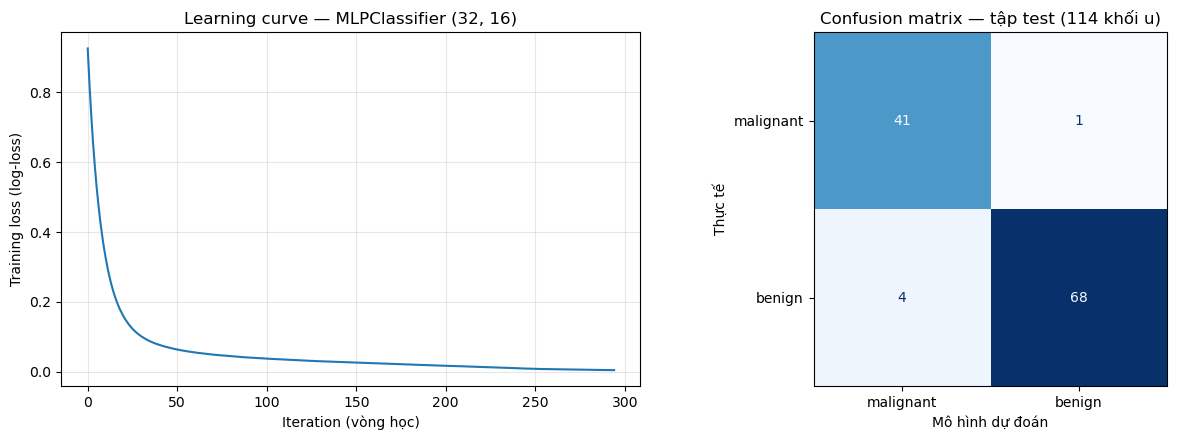

Ác tính thật: 42 → mô hình bắt đúng 41, bỏ sót 1
Lành tính thật: 72 → mô hình đoán đúng 68, báo nhầm thành ác tính 4
Loss cuối cùng (train): 0.0053


In [24]:
# Learning curve và Confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (1) Learning curve: training loss sau mỗi vòng học
axes[0].plot(mlp_clf.loss_curve_, color="tab:blue")
axes[0].set_title("Learning curve — MLPClassifier (32, 16)")
axes[0].set_xlabel("Iteration (vòng học)")
axes[0].set_ylabel("Training loss (log-loss)")
axes[0].grid(alpha=0.3)

# (2) Confusion matrix trên tập test
cm = confusion_matrix(yc_test, yc_pred)
ConfusionMatrixDisplay(cm, display_labels=cancer.target_names).plot(
    ax=axes[1], cmap="Blues", colorbar=False, values_format="d"
)
axes[1].set_title("Confusion matrix — tập test (114 khối u)")
axes[1].set_xlabel("Mô hình dự đoán")
axes[1].set_ylabel("Thực tế")

plt.tight_layout()
plt.show()

# Đọc confusion matrix bằng lời
tn_m, fn_m = cm[0, 0], cm[0, 1]   # hàng "malignant" thật
fp_m, tn_b = cm[1, 0], cm[1, 1]   # hàng "benign" thật
print(f"Ác tính thật: {tn_m + fn_m} → mô hình bắt đúng {tn_m}, bỏ sót {fn_m}")
print(f"Lành tính thật: {fp_m + tn_b} → mô hình đoán đúng {tn_b}, báo nhầm thành ác tính {fp_m}")
print(f"Loss cuối cùng (train): {mlp_clf.loss_:.4f}")

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — Kết quả phân loại:</b>
<ul>
<li><b>Learning curve:</b> mức lỗi (loss) giảm rất nhanh trong khoảng 30 vòng đầu (từ khoảng 0.93 xuống dưới 0.2), sau đó giảm chậm dần và gần chạm 0 (0.0053) ở vòng 295, thì mô hình tự dừng vì không cải thiện thêm. Đường cong mượt, không có gai lớn. Loss gần bằng 0 nghĩa là mô hình đã đoán đúng gần như tuyệt đối trên dữ liệu học — đúng như train accuracy = 100%.</li>
<li><b>Confusion matrix (114 khối u của tập test):</b>
<ul>
<li>42 khối u ác tính thật: mô hình bắt đúng <b>41</b>, <b>bỏ sót 1</b> (đoán nhầm thành lành tính).</li>
<li>72 khối u lành tính thật: mô hình đoán đúng <b>68</b>, <b>báo nhầm 4</b> thành ác tính.</li>
<li>Tổng cộng đúng 109/114 khối u → accuracy = 95,6%.</li>
</ul></li>
<li><b>Precision và recall (lớp ác tính):</b>
<ul>
<li><b>Recall = 0.976</b> — "trong các ca ác tính thật, mô hình bắt được bao nhiêu?": 42 ca ác tính thật, mô hình phát hiện được 41 ca, chỉ bỏ sót 1.</li>
<li><b>Precision = 0.911</b> — "trong những lần mô hình báo ác tính, đúng được bao nhiêu?": mô hình báo "ác tính" 45 lần, đúng 41 lần, báo nhầm 4 lần.</li>
</ul>
Thông thường hai chỉ số này không thể cùng hoàn hảo: nếu mô hình báo "ác tính" dễ hơn thì sẽ bắt được nhiều ca bệnh hơn, nhưng cũng báo nhầm nhiều người khỏe hơn. Mô hình này đang nghiêng về phía <b>bỏ sót ít</b> (recall 0.976 cao hơn precision 0.911). Với chẩn đoán ung thư, đây là lựa chọn hợp lý: báo nhầm chỉ khiến bệnh nhân phải xét nghiệm thêm, còn bỏ sót thì bệnh nhân bị ung thư mà không được điều trị — nguy hiểm hơn nhiều.</li>
<li><b>Mô hình có tổng quát hóa tốt không:</b> có, nhưng có dấu hiệu học vẹt nhẹ. Trên dữ liệu học, mô hình đúng 100% (455/455) và loss gần bằng 0, tức là nó đã thuộc lòng hoàn toàn dữ liệu học. Trên dữ liệu mới, độ chính xác còn 95,6% — thấp hơn khoảng 4,4 điểm phần trăm. Tuy vậy, 95,6% vẫn rất cao: nếu chỉ đoán bừa "lành tính" cho mọi khối u thì cũng đúng được 62,7%, mô hình vượt xa mức đó. Khoảng chênh giữa train và test sẽ được xử lý ở mục 2.4 (Early Stopping — dừng học sớm trước khi mô hình học thuộc lòng).</li>
</ul>
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">2.3 Optimiser Comparison [8 pts]</div>
Huấn luyện cùng một kiến trúc ở mục 2.2 (2 lớp ẩn (32, 16), ReLU, <code>max_iter=500</code>, <code>random_state=42</code>) với 3 optimizer — tức 3 "cách học" khác nhau:
<ul>
<li><b>SGD:</b> học từng nhóm nhỏ dữ liệu, mỗi lần sửa một bước có độ dài cố định.</li>
<li><b>Adam:</b> cũng học từng nhóm nhỏ, nhưng tự điều chỉnh độ dài bước sửa cho từng trọng số.</li>
<li><b>L-BFGS:</b> mỗi bước dùng toàn bộ dữ liệu cùng lúc và tính toán kỹ hướng sửa tốt nhất; mỗi bước tốn công hơn nhưng cần ít bước hơn.</li>
</ul>
<i>Lưu ý:</i> sklearn không lưu đường loss (<code>loss_curve_</code>) cho L-BFGS, nên đường này được tạo bằng cách huấn luyện L-BFGS lần lượt với 1, 2, 3, … bước và ghi lại loss sau mỗi lần. Với SGD và Adam, mỗi "iteration" là một vòng học qua toàn bộ dữ liệu; với L-BFGS, mỗi iteration là một bước sửa dùng toàn bộ dữ liệu.
</div>

In [25]:
# 2.3 Huấn luyện cùng một kiến trúc với 3 optimizer
import warnings
from sklearn.exceptions import ConvergenceWarning

base_params = dict(hidden_layer_sizes=(32, 16), activation="relu", max_iter=500, random_state=42)
curves, rows = {}, []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)

    for solver in ["sgd", "adam", "lbfgs"]:
        model = MLPClassifier(solver=solver, **base_params)
        start = time.time()
        model.fit(Xc_train_scaled, yc_train)
        fit_time = time.time() - start

        if solver == "lbfgs":
            # Tự ghi lại loss sau mỗi bước của L-BFGS (L-BFGS cho kết quả giống hệt nhau mỗi lần chạy,
            # nên huấn luyện với max_iter = k cho đúng loss tại bước thứ k)
            curves[solver] = [
                MLPClassifier(solver="lbfgs", **{**base_params, "max_iter": k})
                .fit(Xc_train_scaled, yc_train).loss_
                for k in range(1, model.n_iter_ + 1)
            ]
        else:
            curves[solver] = model.loss_curve_

        rows.append({
            "Optimizer": solver.upper() if solver != "lbfgs" else "L-BFGS",
            "Số iteration": model.n_iter_,
            "Loss cuối": model.loss_,
            "Train accuracy": model.score(Xc_train_scaled, yc_train),
            "Test accuracy": model.score(Xc_test_scaled, yc_test),
            "Thời gian (s)": fit_time,
        })

solver_table = pd.DataFrame(rows).round(4)
solver_table

,Optimizer,Số iteration,Loss cuối,Train accuracy,Test accuracy,Thời gian (s)
0,SGD,331,0.0584,0.989,0.9825,0.5782
1,ADAM,295,0.0053,1.000,0.9561,0.4370
2,L-BFGS,16,0.0001,1.000,0.9474,0.0504


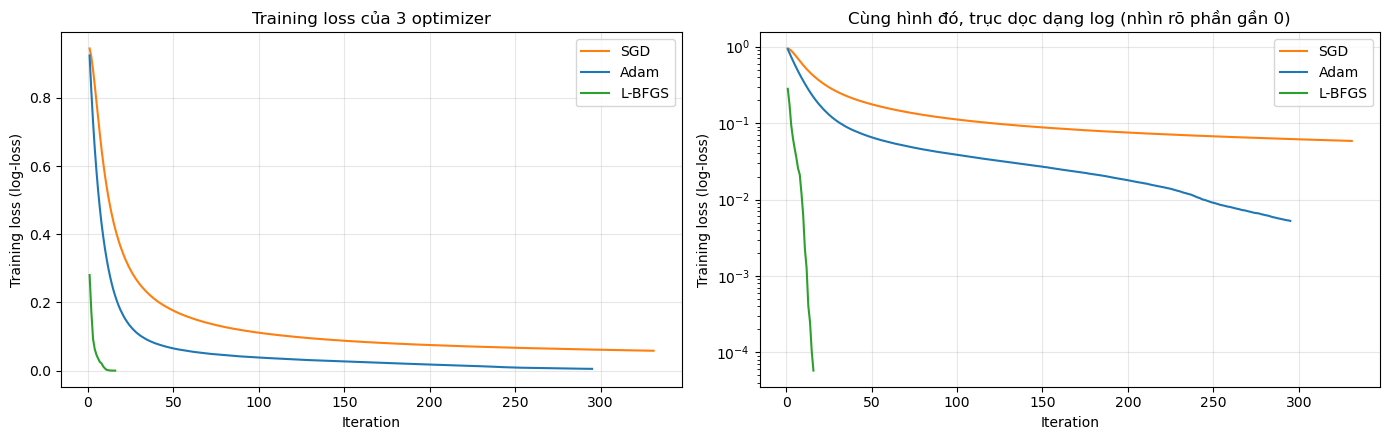

In [26]:
# Vẽ 3 đường loss trên cùng một hình
labels = {"sgd": "SGD", "adam": "Adam", "lbfgs": "L-BFGS"}
colors = {"sgd": "tab:orange", "adam": "tab:blue", "lbfgs": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for solver, curve in curves.items():
    for ax in axes:
        ax.plot(range(1, len(curve) + 1), curve, label=labels[solver], color=colors[solver])

axes[0].set_title("Training loss của 3 optimizer")
axes[1].set_title("Cùng hình đó, trục dọc dạng log (nhìn rõ phần gần 0)")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Training loss (log-loss)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — So sánh 3 optimizer:</b>
<ul>
<li><b>Tốc độ:</b> L-BFGS nhanh vượt trội: chỉ cần <b>16 bước</b> và <b>0,05 giây</b>. Adam cần 295 vòng (0,44 giây), SGD cần 331 vòng (0,58 giây). L-BFGS nhanh vì mỗi bước nó xem toàn bộ 455 khối u cùng lúc rồi tính toán kỹ hướng sửa, nên mỗi bước sửa được rất nhiều; ngay sau bước đầu tiên, loss của L-BFGS đã chỉ còn khoảng 0.28, trong khi SGD và Adam vẫn ở khoảng 0.93. Còn SGD chậm nhất vì mỗi lần chỉ sửa một bước nhỏ, độ dài cố định.</li>
<li><b>Độ ổn định:</b> cả 3 đường loss đều đi xuống đều đặn, không có gai. Đường SGD giảm từ từ và đều nhất; Adam giảm nhanh hơn SGD ngay từ đầu; L-BFGS lao thẳng xuống gần 0 chỉ trong vài bước.</li>
<li><b>Loss cuối cùng:</b> L-BFGS thấp nhất (0.0001), tiếp theo là Adam (0.0053), SGD cao nhất (0.0584). Nghĩa là L-BFGS và Adam đã đoán đúng gần như tuyệt đối trên dữ liệu học (train accuracy 100%), còn SGD thì chưa (98,9%).</li>
<li><b>Điểm đáng chú ý — loss thấp nhất không có nghĩa là tốt nhất:</b> trên dữ liệu mới (114 khối u của tập test), thứ tự lại đảo ngược: SGD đúng 98,2% (112/114), Adam 95,6% (109/114), L-BFGS 94,7% (108/114). Cách nào học thuộc dữ liệu học kỹ nhất thì lại làm kém nhất trên dữ liệu mới — dấu hiệu của học vẹt. SGD học chậm nên chưa kịp thuộc lòng, nhờ vậy lại đoán tốt hơn trên dữ liệu mới. Tuy nhiên, ba cách chỉ chênh nhau 3–4 khối u trên 114, nên chưa thể khẳng định chắc chắn cách nào tốt hơn hẳn.</li>
<li><b>Tóm lại:</b> với bộ dữ liệu nhỏ như thế này, <b>L-BFGS</b> là lựa chọn nhanh nhất; <b>Adam</b> nhanh và ổn định, là lựa chọn mặc định an toàn; <b>SGD</b> chậm nhất nhưng ít bị học vẹt hơn trong thí nghiệm này. BFGS phải xem toàn bộ dữ liệu ở mỗi bước, nên với dữ liệu rất lớn nó sẽ chậm và tốn bộ nhớ — khi đó SGD hoặc Adam phù hợp hơn.</li>
</ul>
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">2.4 Early Stopping [7 pts]</div>
Early stopping (dừng học sớm): tách riêng 10% dữ liệu học làm "đề thi thử" (validation set). Sau mỗi vòng học, mô hình được chấm điểm trên đề thi thử; nếu 10 vòng liên tiếp điểm không tăng thì dừng lại, và sklearn tự quay về phiên bản mô hình có điểm thi thử cao nhất. So sánh hai mô hình cùng kiến trúc ở mục 2.2 (2 lớp ẩn (32, 16), ReLU, Adam):
<ul>
<li><b>(a) Baseline:</b> <code>early_stopping=False</code>, <code>max_iter=500</code></li>
<li><b>(b) Early stopping:</b> <code>early_stopping=True</code>, <code>validation_fraction=0.1</code>, <code>n_iter_no_change=10</code>, <code>max_iter=500</code></li>
</ul>
</div>

In [27]:
# 2.4 Huấn luyện 2 mô hình: (a) không dừng sớm, (b) có dừng sớm
arch = dict(hidden_layer_sizes=(32, 16), activation="relu", solver="adam", max_iter=500, random_state=42)

model_a = MLPClassifier(early_stopping=False, **arch)
model_b = MLPClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, **arch)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    model_a.fit(Xc_train_scaled, yc_train)
    model_b.fit(Xc_train_scaled, yc_train)

stop_epoch = model_b.n_iter_                                   # vòng mà early stopping dừng lại
best_epoch = int(np.argmax(model_b.validation_scores_)) + 1    # vòng có điểm thi thử cao nhất (mô hình được giữ lại)

es_table = pd.DataFrame({
    "Mô hình": ["(a) Không dừng sớm", "(b) Early stopping"],
    "Số iteration": [model_a.n_iter_, model_b.n_iter_],
    "Train accuracy": [model_a.score(Xc_train_scaled, yc_train), model_b.score(Xc_train_scaled, yc_train)],
    "Test accuracy": [model_a.score(Xc_test_scaled, yc_test), model_b.score(Xc_test_scaled, yc_test)],
}).round(4)

print(f"(b) dừng ở vòng {stop_epoch}; vòng có điểm thi thử cao nhất: {best_epoch} "
      f"(validation accuracy = {model_b.best_validation_score_:.4f})")
print(f"Số iteration tiết kiệm được: {model_a.n_iter_ - model_b.n_iter_} "
      f"({(model_a.n_iter_ - model_b.n_iter_) / model_a.n_iter_ * 100:.0f}%)")
es_table

(b) dừng ở vòng 25; vòng có điểm thi thử cao nhất: 14 (validation accuracy = 0.9565)
Số iteration tiết kiệm được: 270 (92%)


,Mô hình,Số iteration,Train accuracy,Test accuracy
0,(a) Không dừng sớm,295,1.0000,0.9561
1,(b) Early stopping,25,0.9495,0.9211


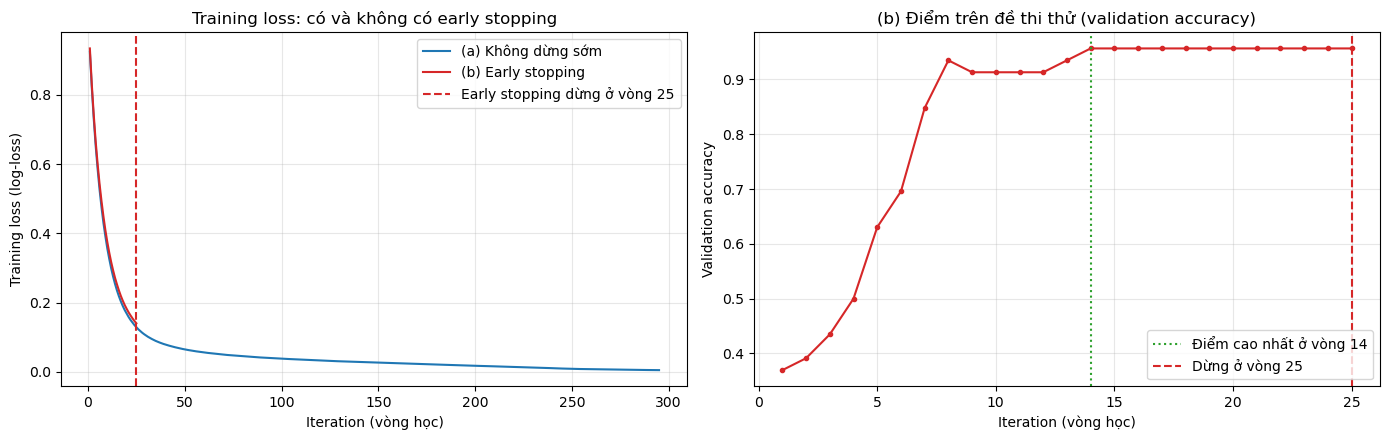

In [28]:
# Vẽ 2 đường training loss trên cùng một hình, đánh dấu vòng early stopping dừng lại
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(range(1, len(model_a.loss_curve_) + 1), model_a.loss_curve_, color="tab:blue", label="(a) Không dừng sớm")
axes[0].plot(range(1, len(model_b.loss_curve_) + 1), model_b.loss_curve_, color="tab:red", label="(b) Early stopping")
axes[0].axvline(stop_epoch, color="tab:red", linestyle="--", label=f"Early stopping dừng ở vòng {stop_epoch}")
axes[0].set_title("Training loss: có và không có early stopping")
axes[0].set_xlabel("Iteration (vòng học)")
axes[0].set_ylabel("Training loss (log-loss)")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Điểm "thi thử" (validation accuracy) của mô hình (b) sau mỗi vòng
axes[1].plot(range(1, len(model_b.validation_scores_) + 1), model_b.validation_scores_, color="tab:red", marker=".")
axes[1].axvline(best_epoch, color="tab:green", linestyle=":", label=f"Điểm cao nhất ở vòng {best_epoch}")
axes[1].axvline(stop_epoch, color="tab:red", linestyle="--", label=f"Dừng ở vòng {stop_epoch}")
axes[1].set_title("(b) Điểm trên đề thi thử (validation accuracy)")
axes[1].set_xlabel("Iteration (vòng học)")
axes[1].set_ylabel("Validation accuracy")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — Early stopping:</b>
<ul>
<li><b>Tiết kiệm được bao nhiêu vòng học:</b> mô hình B (early stopping) dừng ở <b>vòng 25</b>, trong khi mô hình A (không dừng sớm) học đến vòng 295 → tiết kiệm được <b>270 vòng (92%)</b>.</li>
<li><b>Early stopping có giúp đoán tốt hơn trên dữ liệu mới không? — Trong thí nghiệm này thì không.</b> Trên 114 khối u của tập test, mô hình A (không dừng sớm) đúng 95,6% (109/114), còn mô hình B (early stopping) chỉ đúng 92,1% (105/114) — sai thêm 4 khối u.</li>
<li><b>Vì sao mô hình B (early stopping) lại kém hơn:</b> early stopping lấy 10% dữ liệu học làm "đề thi thử", tức chỉ có <b>46 khối u</b>. Ở vòng 14, mô hình đã làm đúng 44/46 câu (95,65%), sau đó điểm đứng yên ở mức này suốt 11 vòng (hình bên phải), nên quy tắc "10 vòng liền không tăng thì dừng" khiến mô hình dừng ở vòng 25. Điểm đứng yên không phải vì mô hình bắt đầu học vẹt, mà vì đề thi thử quá ít câu: chỉ còn 2 câu sai, muốn tăng điểm thì phải làm đúng thêm hẳn một khối u. Kết quả là mô hình dừng khi chưa học xong: ở vòng 25, loss vẫn còn khoảng 0.13 (hình bên trái), trong khi mô hình A (không dừng sớm) tiếp tục giảm xuống gần 0; ngay cả trên dữ liệu học, mô hình B (early stopping) cũng chỉ đúng 95% so với 100% của mô hình A (không dừng sớm). Ngoài ra, mô hình B (early stopping) chỉ được học trên 409 khối u (vì phải cất 46 khối u làm đề thi thử), ít hơn 455 khối u của mô hình A (không dừng sớm).</li>
<li><b>Ưu và nhược điểm của early stopping:</b>
<ul>
<li><b>Ưu điểm:</b> tiết kiệm rất nhiều thời gian học (ở đây 92% số vòng), và tự động dừng trước khi mô hình học vẹt mà không cần đoán trước nên học bao nhiêu vòng.</li>
<li><b>Nhược điểm:</b> phải cắt bớt một phần dữ liệu học để làm đề thi thử; và khi dữ liệu nhỏ, đề thi thử quá ít câu nên điểm thi thử không đáng tin, dễ khiến mô hình dừng quá sớm — đúng như những gì xảy ra ở đây.</li>
</div>

<hr>
<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:18px; font-weight:700;">PART 3 — Deep Learning with PyTorch (40 pts)</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">3.1 PyTorch Fundamentals Review [5 pts]</div>
Ba bài tập khởi động: (1) tạo và chuẩn hóa một tensor ngẫu nhiên đại diện cho một ảnh RGB; (2) so sánh tốc độ nhân ma trận trên CPU và GPU; (3) dùng <code>autograd</code> để tính đạo hàm và kiểm tra lại bằng tính tay.
</div>

In [29]:
# 3.1 (1) Tensor ngẫu nhiên đại diện cho một ảnh RGB: 3 kênh màu × 224 × 224 điểm ảnh
torch.manual_seed(42)
img = torch.rand(3, 224, 224)

# Chuẩn hóa về trung bình 0, độ lệch chuẩn 1
img_norm = (img - img.mean()) / img.std()

print("Trước khi chuẩn hóa:")
print(f"  shape={tuple(img.shape)}, dtype={img.dtype}, mean={img.mean():.4f}, std={img.std():.4f}")
print("Sau khi chuẩn hóa:")
print(f"  shape={tuple(img_norm.shape)}, dtype={img_norm.dtype}, mean={img_norm.mean():.4f}, std={img_norm.std():.4f}")

Trước khi chuẩn hóa:
  shape=(3, 224, 224), dtype=torch.float32, mean=0.5009, std=0.2890
Sau khi chuẩn hóa:
  shape=(3, 224, 224), dtype=torch.float32, mean=0.0000, std=1.0000


In [30]:
# 3.1 (2) So sánh tốc độ nhân ma trận 2048×2048 trên CPU và GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "không có")

A = torch.randn(2048, 2048)
B = torch.randn(2048, 2048)
n_runs = 10

# CPU
_ = A @ B                                  # chạy thử 1 lần cho "nóng máy"
start = time.perf_counter()
for _ in range(n_runs):
    C_cpu = A @ B
cpu_time = (time.perf_counter() - start) / n_runs

# GPU
if torch.cuda.is_available():
    A_gpu, B_gpu = A.to(device), B.to(device)
    _ = A_gpu @ B_gpu                      # chạy thử (lần đầu GPU cần khởi động)
    torch.cuda.synchronize()               # chờ GPU làm xong rồi mới bấm giờ
    start = time.perf_counter()
    for _ in range(n_runs):
        C_gpu = A_gpu @ B_gpu
    torch.cuda.synchronize()               # GPU chạy bất đồng bộ → phải chờ xong mới dừng đồng hồ
    gpu_time = (time.perf_counter() - start) / n_runs

    print(f"CPU: {cpu_time * 1000:.2f} ms / lần nhân")
    print(f"GPU: {gpu_time * 1000:.2f} ms / lần nhân")
    print(f"→ GPU nhanh hơn CPU khoảng {cpu_time / gpu_time:.1f} lần")
    print("Kết quả CPU và GPU khớp nhau:", torch.allclose(C_cpu, C_gpu.cpu(), rtol=1e-3, atol=1e-2))
else:
    print(f"CPU: {cpu_time * 1000:.2f} ms / lần nhân (không có GPU để so sánh)")

Thiết bị GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CPU: 67.62 ms / lần nhân
GPU: 2.27 ms / lần nhân
→ GPU nhanh hơn CPU khoảng 29.7 lần
Kết quả CPU và GPU khớp nhau: True


<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Kết quả so sánh tốc độ:</b> nhân hai ma trận 2048×2048, CPU mất <b>67,62 ms</b> mỗi lần, còn GPU NVIDIA GeForce RTX 4060 Laptop chỉ mất <b>2,27 ms</b> → <b>GPU nhanh hơn CPU khoảng 29,7 lần</b>, và kết quả của hai bên khớp nhau. Lý do: CPU có ít nhân nhưng mỗi nhân mạnh, phù hợp làm từng việc phức tạp lần lượt; GPU có hàng nghìn nhân nhỏ cùng làm song song. Nhân ma trận gồm hàng tỉ phép nhân–cộng giống hệt nhau và độc lập với nhau, nên GPU chia ra làm cùng lúc được. Huấn luyện mạng nơ-ron chủ yếu là các phép nhân ma trận như vậy, đó là lý do các phần tiếp theo (huấn luyện CNN và ResNet) được chạy trên GPU.
</div>

In [31]:
# 3.1 (3) Autograd: f(x) = (x² + 3x − 2)³, tính df/dx tại x = 2
x = torch.tensor(2.0, requires_grad=True)   # requires_grad=True: yêu cầu PyTorch theo dõi để tính đạo hàm
f = (x**2 + 3*x - 2) ** 3
f.backward()                                # PyTorch tự tính đạo hàm, lưu vào x.grad

# Tính tay: df/dx = 3·(x² + 3x − 2)² · (2x + 3)
x0 = 2.0
manual = 3 * (x0**2 + 3*x0 - 2) ** 2 * (2*x0 + 3)

print(f"f(2)                 = {f.item():.1f}")
print(f"df/dx tại x=2 (autograd) = {x.grad.item():.1f}")
print(f"df/dx tại x=2 (tính tay) = {manual:.1f}")
print("Hai kết quả khớp nhau:", torch.isclose(x.grad, torch.tensor(manual)).item())

f(2)                 = 512.0
df/dx tại x=2 (autograd) = 1344.0
df/dx tại x=2 (tính tay) = 1344.0
Hai kết quả khớp nhau: True


<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Kiểm tra đạo hàm bằng tính tay:</b> đặt u = x² + 3x − 2, khi đó f = u³. Theo quy tắc đạo hàm hàm hợp:
<ul>
<li>du/dx = 2x + 3</li>
<li>df/dx = 3u² · du/dx = 3·(x² + 3x − 2)² · (2x + 3)</li>
<li>Tại x = 2: u = 4 + 6 − 2 = 8, và 2x + 3 = 7</li>
<li>df/dx = 3 · 8² · 7 = 3 · 64 · 7 = <b>1344</b></li>
</ul>
Autograd của PyTorch cũng tính ra <code>x.grad</code> = <b>1344.0</b> → <b>khớp hoàn toàn với tính tay</b>. Điều này cho thấy PyTorch tự động áp dụng đúng quy tắc đạo hàm hàm hợp — đây cũng chính là cách PyTorch tính "nên sửa trọng số theo hướng nào, mạnh bao nhiêu" khi huấn luyện mạng nơ-ron.
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">3.2 CNN for CIFAR-10 Image Classification [20 pts]</div>
<div style="font-size:15px; font-weight:700; margin-top:6px;">3.2.1 Data Loading &amp; Augmentation [4 pts]</div>
CIFAR-10 gồm 60.000 ảnh màu 32×32 thuộc 10 loại (50.000 ảnh train, 10.000 ảnh test). Augmentation cho tập train: <b>lật ngang ngẫu nhiên</b> và <b>cắt ngẫu nhiên 32×32 sau khi thêm viền 4 điểm ảnh</b> — mỗi vòng học, cùng một ảnh sẽ hơi khác đi, giúp mô hình học đặc điểm chung của từng loại thay vì học thuộc từng ảnh. Sau đó chuẩn hóa từng kênh màu theo trung bình và độ lệch chuẩn của CIFAR-10.<br>
Để vẽ được đường loss/accuracy trên tập validation ở mục 3.2.3, tách 5.000 ảnh từ tập train làm <b>validation</b> (không augmentation): còn 45.000 ảnh train, 5.000 ảnh validation, 10.000 ảnh test.
</div>

In [34]:
# 3.2.1 Tải CIFAR-10, augmentation, DataLoader
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

torch.manual_seed(42)

# Trung bình và độ lệch chuẩn của từng kênh màu (R, G, B) trên tập train CIFAR-10
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

train_transform = T.Compose([
    T.RandomHorizontalFlip(),                 # lật ngang ngẫu nhiên (xác suất 50%)
    T.RandomCrop(32, padding=4),              # thêm viền 4 điểm ảnh rồi cắt ngẫu nhiên 32×32
    T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
])
test_transform = T.Compose([                  # validation/test: không biến dạng, chỉ chuẩn hóa
    T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
])

DATA_DIR = "./data"   # dữ liệu (~170 MB) được tải về thư mục Lab2/data trong lần chạy đầu
train_full_aug   = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=train_transform)
train_full_plain = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=test_transform)
test_set         = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=test_transform)
classes = train_full_aug.classes

# Tách 45.000 ảnh train / 5.000 ảnh validation (cố định bằng seed 42)
perm = torch.randperm(len(train_full_aug), generator=torch.Generator().manual_seed(42)).tolist()
train_set = Subset(train_full_aug, perm[:45000])
val_set   = Subset(train_full_plain, perm[45000:])

loader_args = dict(batch_size=64, num_workers=2, pin_memory=True, persistent_workers=True)
train_loader = DataLoader(train_set, shuffle=True,  **loader_args)
val_loader   = DataLoader(val_set,   shuffle=False, **loader_args)
test_loader  = DataLoader(test_set,  shuffle=False, **loader_args)

print("Các loại:", classes)
print(f"Train: {len(train_set)} ảnh | Validation: {len(val_set)} ảnh | Test: {len(test_set)} ảnh")
print(f"Số batch mỗi vòng học: {len(train_loader)} (batch size = 64)")

100%|██████████| 170M/170M [55:58<00:00, 50.8kB/s]   


Các loại: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train: 45000 ảnh | Validation: 5000 ảnh | Test: 10000 ảnh
Số batch mỗi vòng học: 704 (batch size = 64)


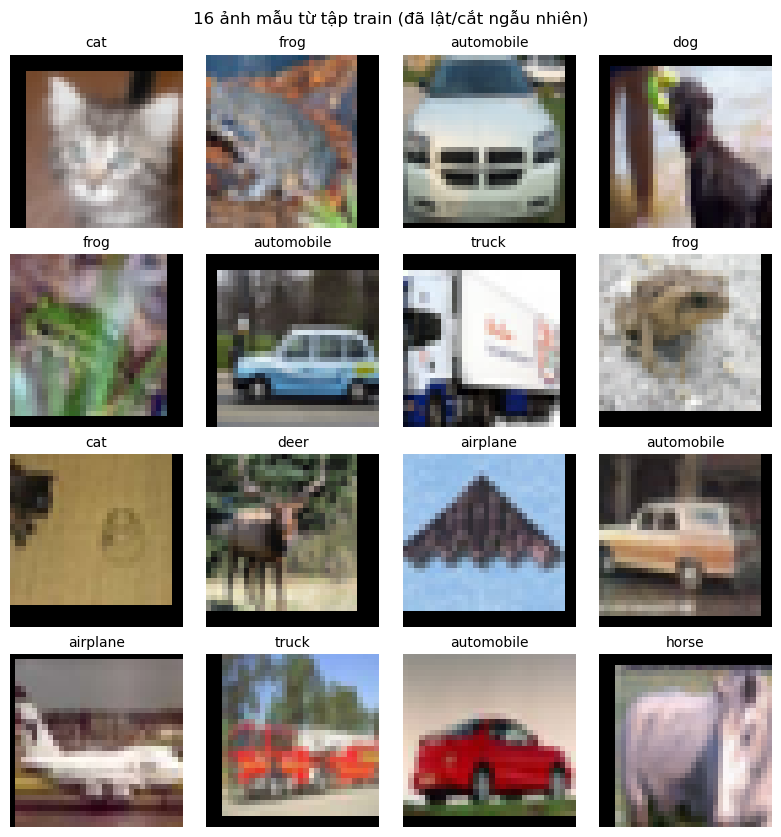

In [35]:
# Hiển thị 16 ảnh mẫu (đã qua augmentation) kèm tên loại
images, labels = next(iter(train_loader))

mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR_STD).view(3, 1, 1)

fig, axes = plt.subplots(4, 4, figsize=(8, 8.5))
for i, ax in enumerate(axes.flat):
    img = (images[i] * std + mean).clamp(0, 1)   # bỏ chuẩn hóa để hiển thị đúng màu
    ax.imshow(img.permute(1, 2, 0).numpy())       # (C, H, W) → (H, W, C) cho matplotlib
    ax.set_title(classes[labels[i]], fontsize=10)
    ax.axis("off")
plt.suptitle("16 ảnh mẫu từ tập train (đã lật/cắt ngẫu nhiên)", fontsize=12)
plt.tight_layout()
plt.show()

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:15px; font-weight:700;">3.2.2 Custom CNN Architecture [8 pts]</div>
Xây mạng CNN theo đúng thiết kế của đề:
<ul>
<li><b>Block 1:</b> Conv(3→32) → BN → ReLU → Conv(32→32) → BN → ReLU → MaxPool(2×2) — tìm các đặc điểm đơn giản (cạnh, góc, mảng màu); ảnh thu nhỏ 32×32 → 16×16.</li>
<li><b>Block 2:</b> Conv(32→64) → BN → ReLU → Conv(64→64) → BN → ReLU → MaxPool(2×2) — ghép thành hình dạng phức tạp hơn; ảnh thu nhỏ 16×16 → 8×8.</li>
<li><b>Block 3:</b> Conv(64→128) → BN → ReLU → AdaptiveAvgPool(1×1) — tóm tắt toàn bộ ảnh thành 128 con số.</li>
<li><b>Classifier:</b> Flatten → Dropout(0.5) → Linear(128→256) → ReLU → Linear(256→10) — quyết định ảnh thuộc loại nào trong 10 loại.</li>
</ul>
Tất cả các lớp Conv dùng kernel 3×3, padding = 1 (giữ nguyên kích thước ảnh). BN (Batch Normalization) chuẩn hóa dữ liệu bên trong mạng để học ổn định hơn; Dropout(0.5) tắt ngẫu nhiên một nửa số neuron khi học để giảm học vẹt.
</div>

In [39]:
# 3.2.2 Custom CNN theo thiết kế của đề
class CustomCNN(nn.Module):
    """
    Block 1 : Conv(3→32, 3×3, pad=1) → BN → ReLU → Conv(32→32, 3×3, pad=1) → BN → ReLU → MaxPool(2×2)
    Block 2 : Conv(32→64, 3×3, pad=1) → BN → ReLU → Conv(64→64, 3×3, pad=1) → BN → ReLU → MaxPool(2×2)
    Block 3 : Conv(64→128, 3×3, pad=1) → BN → ReLU → AdaptiveAvgPool(1×1)
    Classifier: Flatten → Dropout(0.5) → Linear(128→256) → ReLU → Linear(256→10)
    """
    def __init__(self, num_classes=10):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128, 256), nn.ReLU(inplace=True),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.classifier(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

cnn = CustomCNN().to(device)
print(cnn)
print(f"\nTổng số tham số huấn luyện được (trainable parameters): {count_params(cnn):,}")

CustomCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2

In [40]:
# Kiểm tra forward pass với một batch giả (4, 3, 32, 32) và theo dõi kích thước qua từng block
cnn.eval()
with torch.no_grad():
    x = torch.randn(4, 3, 32, 32, device=device)
    print(f"Input       : {tuple(x.shape)}")
    x = cnn.block1(x);     print(f"Sau block 1 : {tuple(x.shape)}")
    x = cnn.block2(x);     print(f"Sau block 2 : {tuple(x.shape)}")
    x = cnn.block3(x);     print(f"Sau block 3 : {tuple(x.shape)}")
    out = cnn.classifier(x); print(f"Output      : {tuple(out.shape)}  → 4 ảnh × 10 điểm số (mỗi loại một điểm)")
print("Forward pass thành công:", out.shape == (4, 10))

Input       : (4, 3, 32, 32)
Sau block 1 : (4, 32, 16, 16)
Sau block 2 : (4, 64, 8, 8)
Sau block 3 : (4, 128, 1, 1)
Output      : (4, 10)  → 4 ảnh × 10 điểm số (mỗi loại một điểm)
Forward pass thành công: True


<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:15px; font-weight:700;">3.2.3 Training Loop [8 pts]</div>
Huấn luyện <b>30 epoch</b> với optimizer <b>Adam (lr = 0.001)</b> và hàm lỗi <b>Cross-Entropy</b>. Dùng <b>StepLR</b> giảm learning rate 10 lần sau mỗi 10 epoch (epoch 1–10: 0.001, epoch 11–20: 0.0001, epoch 21–30: 0.00001): lúc đầu bước sửa lớn để tiến nhanh, về sau bước nhỏ để tinh chỉnh. Sau mỗi epoch ghi lại loss và accuracy trên tập train và validation; cuối cùng đánh giá trên tập test.
</div>

In [42]:
# Các hàm huấn luyện dùng chung (dùng lại cho ResNet ở mục 3.3.2)
import copy, json

torch.backends.cudnn.benchmark = True        # để cuDNN tự chọn cách tính tích chập nhanh nhất cho GPU
criterion = nn.CrossEntropyLoss()


def run_epoch(model, loader, optimizer=None):
    """Chạy 1 epoch. Có optimizer → huấn luyện; không có → chỉ đánh giá. Trả về (loss, accuracy)."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def fit(model, optimizer, scheduler, epochs, name):
    """Huấn luyện `epochs` vòng, in kết quả từng vòng, trả về lịch sử và tổng thời gian (giây)."""
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        lr = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        scheduler.step()                                   # cập nhật learning rate sau mỗi epoch
        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc, lr]):
            history[k].append(v)
        print(f"[{name}] Epoch {epoch:2d}/{epochs} | lr={lr:.0e} | "
              f"train loss {tr_loss:.4f}, acc {tr_acc:.4f} | val loss {va_loss:.4f}, acc {va_acc:.4f} | "
              f"{time.time() - start:6.0f}s")
    return history, time.time() - start


def plot_history(history, title):
    """Vẽ loss và accuracy của train/validation theo từng epoch."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs, history["train_loss"], "o-", ms=3, label="Train")
    axes[0].plot(epochs, history["val_loss"], "o-", ms=3, label="Validation")
    axes[0].set_title(f"{title} — Loss")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[1].plot(epochs, history["train_acc"], "o-", ms=3, label="Train")
    axes[1].plot(epochs, history["val_acc"], "o-", ms=3, label="Validation")
    axes[1].set_title(f"{title} — Accuracy")
    axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

In [43]:
# Huấn luyện CustomCNN: 30 epoch, Adam (lr=0.001), StepLR giảm ×0.1 mỗi 10 epoch (≈ 10–15 phút trên GPU)
torch.manual_seed(42)
cnn = CustomCNN().to(device)
optimizer_cnn = torch.optim.Adam(cnn.parameters(), lr=0.001)
scheduler_cnn = torch.optim.lr_scheduler.StepLR(optimizer_cnn, step_size=10, gamma=0.1)

history_cnn, time_cnn = fit(cnn, optimizer_cnn, scheduler_cnn, epochs=30, name="CustomCNN")

# Đánh giá trên tập test
test_loss_cnn, test_acc_cnn = run_epoch(cnn, test_loader)
print(f"\nThời gian huấn luyện: {time_cnn / 60:.1f} phút")
print(f"Test loss: {test_loss_cnn:.4f} | Test accuracy: {test_acc_cnn:.4f}")

# Lưu mô hình và kết quả ra file, để không phải huấn luyện lại nếu kernel bị restart
torch.save(cnn.state_dict(), "custom_cnn.pt")
with open("custom_cnn_history.json", "w") as f:
    json.dump({"history": history_cnn, "time": time_cnn, "test_acc": test_acc_cnn, "test_loss": test_loss_cnn}, f)
print("Đã lưu: custom_cnn.pt, custom_cnn_history.json")

[CustomCNN] Epoch  1/30 | lr=1e-03 | train loss 1.5173, acc 0.4322 | val loss 1.2758, acc 0.5452 |     20s
[CustomCNN] Epoch  2/30 | lr=1e-03 | train loss 1.1720, acc 0.5747 | val loss 1.2179, acc 0.5800 |     30s
[CustomCNN] Epoch  3/30 | lr=1e-03 | train loss 1.0449, acc 0.6236 | val loss 1.0257, acc 0.6398 |     38s
[CustomCNN] Epoch  4/30 | lr=1e-03 | train loss 0.9648, acc 0.6551 | val loss 0.9544, acc 0.6596 |     47s
[CustomCNN] Epoch  5/30 | lr=1e-03 | train loss 0.8978, acc 0.6796 | val loss 0.8141, acc 0.7130 |     57s
[CustomCNN] Epoch  6/30 | lr=1e-03 | train loss 0.8468, acc 0.7021 | val loss 0.7735, acc 0.7318 |     67s
[CustomCNN] Epoch  7/30 | lr=1e-03 | train loss 0.7962, acc 0.7210 | val loss 0.8399, acc 0.7156 |     76s
[CustomCNN] Epoch  8/30 | lr=1e-03 | train loss 0.7632, acc 0.7318 | val loss 0.7936, acc 0.7218 |     86s
[CustomCNN] Epoch  9/30 | lr=1e-03 | train loss 0.7245, acc 0.7492 | val loss 0.7662, acc 0.7450 |     98s
[CustomCNN] Epoch 10/30 | lr=1e-03 | 

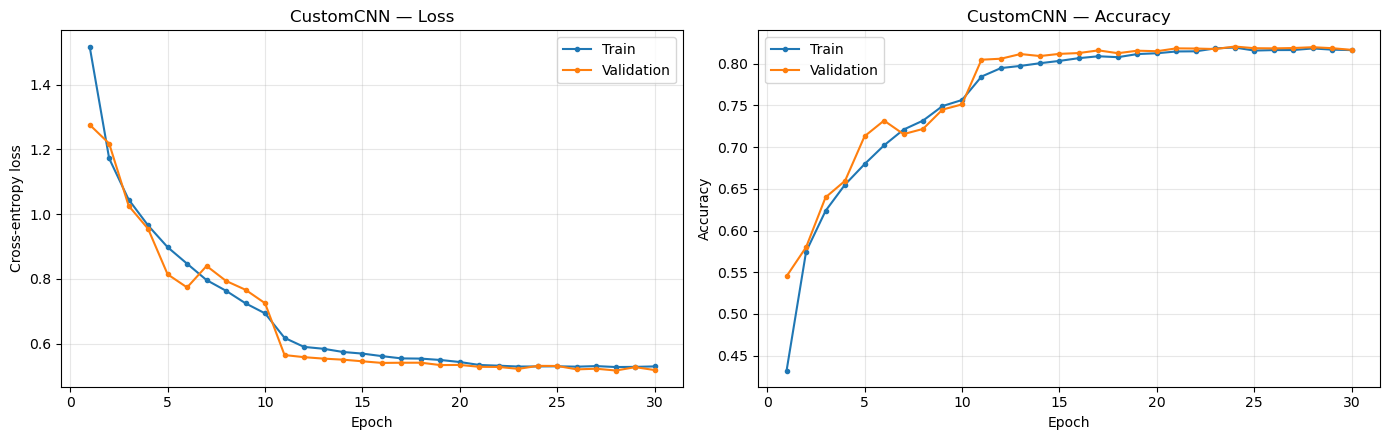

In [44]:
# Đường loss và accuracy của train/validation
plot_history(history_cnn, "CustomCNN")

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — Kết quả huấn luyện CustomCNN:</b>
<ul>
<li><b>Kết quả cuối cùng:</b> sau 30 epoch (6,2 phút trên GPU), mô hình đạt <b>test accuracy = 81,97%</b> (test loss = 0.524) trên 10.000 ảnh test — tức đoán đúng khoảng 8.200 ảnh. Nếu đoán bừa thì chỉ đúng 10% (1 trong 10 loại).</li>
<li><b>Diễn biến qua các epoch:</b>
<ul>
<li><b>Epoch 1–10</b> (lr = 0.001): mô hình tiến bộ nhanh — validation accuracy tăng từ 54,5% lên 75,1%. Đường validation hơi lên xuống (ví dụ epoch 6 đạt 73,2% nhưng epoch 7 lại giảm còn 71,6%) vì bước sửa còn lớn.</li>
<li><b>Epoch 11</b> (lr giảm còn 0.0001): validation accuracy <b>nhảy vọt từ 75,1% lên 80,5%</b> chỉ trong một epoch (loss giảm từ 0.725 xuống 0.565). Bước sửa nhỏ lại giúp mô hình tinh chỉnh chính xác hơn thay vì cứ dao động quanh đáp án. Đây là tác dụng rõ nhất của StepLR.</li>
<li><b>Epoch 21–30</b> (lr = 0.00001): bước sửa quá nhỏ nên mô hình gần như không học thêm — validation accuracy chỉ dao động quanh 81,7–82,1%.</li>
</ul></li>
<li><b>Mô hình có bị overfitting (học vẹt) không? — Không.</b> Ở epoch 30, train accuracy là 81,6% và validation accuracy là 81,7%; train loss là 0.530 và validation loss là 0.518 — hai đường gần như trùng nhau suốt quá trình học (thậm chí validation còn nhỉnh hơn train một chút). Nếu mô hình học vẹt, đường train sẽ tiếp tục tốt lên trong khi đường validation đứng yên hoặc xấu đi, tạo ra khoảng cách lớn giữa hai đường — điều này không xảy ra. Lý do validation nhỉnh hơn train: khi học, ảnh train bị lật/cắt ngẫu nhiên và Dropout tắt bớt một nửa số neuron, nên bài train "khó" hơn; còn khi chấm validation thì ảnh giữ nguyên và Dropout được tắt.</li>
<li><b>Regularization giúp gì?</b> Mô hình này đã dùng sẵn ba cách chống học vẹt: <b>augmentation</b> (lật/cắt ảnh ngẫu nhiên — mỗi epoch mô hình thấy một phiên bản hơi khác của ảnh nên không thể học thuộc), <b>Dropout(0.5)</b> (tắt ngẫu nhiên một nửa số neuron khi học, buộc mô hình không phụ thuộc vào một vài neuron) và <b>Batch Normalization</b> (giúp học ổn định). Chính nhờ những cách này mà hai đường train và validation đi sát nhau. Nếu bỏ chúng đi, mô hình sẽ dễ học thuộc 45.000 ảnh train và đoán kém hơn trên ảnh mới; khi đó có thể thêm các cách khác như <code>weight_decay</code> (phạt trọng số lớn, giống <code>alpha</code> ở Phần 1) hoặc early stopping (như mục 2.4).</li>
<li><b>Hướng cải thiện:</b> vì mô hình không học vẹt mà kết quả dừng ở khoảng 82%, giới hạn hiện tại nằm ở <b>kích thước mô hình</b> (chỉ 175.658 tham số, 5 lớp tích chập) chứ không phải do học vẹt — thêm regularization lúc này sẽ không giúp đoán tốt hơn. Muốn tốt hơn cần một mạng lớn và sâu hơn — đó là việc sẽ thử với ResNet ở mục 3.3.</li>
</ul>
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:16px; font-weight:700;">3.3 Residual Connections [15 pts]</div>
<div style="font-size:15px; font-weight:700; margin-top:6px;">3.3.1 Residual Block Implementation [7 pts]</div>
Khi mạng rất sâu, tín hiệu học (gradient) phải truyền ngược qua rất nhiều lớp từ lớp cuối về lớp đầu, và có thể bị yếu dần đến mức các lớp đầu gần như không học được. ResNet giải quyết bằng <b>skip connection</b> (đường tắt): đầu ra của mỗi khối = (kết quả qua các lớp tích chập) + (đầu vào giữ nguyên), nhờ đó gradient có thể đi thẳng qua đường tắt về các lớp đầu.
<ul>
<li><b>ResidualBlock:</b> Conv 3×3 → BN → ReLU → Conv 3×3 → BN, cộng với đường tắt, rồi ReLU. Khi số kênh hoặc kích thước ảnh thay đổi (ví dụ 16 → 32 kênh, hoặc stride = 2), đường tắt đi qua một Conv 1×1 + BN để đổi kích thước cho khớp (<i>projection shortcut</i>).</li>
<li><b>BottleneckBlock:</b> Conv 1×1 thu nhỏ số kênh C → C/4 → Conv 3×3 → Conv 1×1 phóng to lại C/4 → C, cộng với đường tắt, rồi ReLU. Phần xử lý chính (Conv 3×3) chạy trên số kênh nhỏ nên tiết kiệm tính toán.</li>
</ul>
Tham số <code>use_skip</code> cho phép tắt đường tắt, dùng để so sánh dòng chảy gradient khi có và không có skip connection.
</div>

In [46]:
# 3.3.1 ResidualBlock và BottleneckBlock
class ResidualBlock(nn.Module):
    """
    Conv(C→C, 3×3, pad=1) → BN → ReLU
    Conv(C→C, 3×3, pad=1) → BN
    + skip connection → ReLU
    Handle dimension mismatch with projection shortcut (1×1 conv).
    """
    def __init__(self, in_channels, out_channels=None, stride=1, use_skip=True):
        super().__init__()
        out_channels = out_channels or in_channels
        self.use_skip = use_skip
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # Projection shortcut: khi số kênh hoặc kích thước ảnh thay đổi → Conv 1×1 + BN để khớp kích thước
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()          # cùng kích thước → đường tắt giữ nguyên đầu vào

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.use_skip:
            out = out + self.shortcut(x)           # skip connection
        return self.relu(out)


class BottleneckBlock(nn.Module):
    """
    Conv(C→C//4, 1×1) → BN → ReLU
    Conv(C//4→C//4, 3×3, pad=1) → BN → ReLU
    Conv(C//4→C, 1×1) → BN
    + skip connection → ReLU
    """
    def __init__(self, channels, use_skip=True):
        super().__init__()
        mid = channels // 4
        self.use_skip = use_skip
        self.conv1 = nn.Conv2d(channels, mid, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid)
        self.conv2 = nn.Conv2d(mid, mid, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(mid)
        self.conv3 = nn.Conv2d(mid, channels, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        if self.use_skip:
            out = out + x                          # skip connection (identity)
        return self.relu(out)


# Kiểm tra kích thước đầu ra của từng loại khối
x = torch.randn(4, 16, 32, 32)
print("ResidualBlock(16)            :", tuple(x.shape), "→", tuple(ResidualBlock(16)(x).shape))
print("ResidualBlock(16→32, stride2):", tuple(x.shape), "→", tuple(ResidualBlock(16, 32, stride=2)(x).shape), "(projection shortcut)")
x64 = torch.randn(4, 64, 16, 16)
print("BottleneckBlock(64)          :", tuple(x64.shape), "→", tuple(BottleneckBlock(64)(x64).shape))

ResidualBlock(16)            : (4, 16, 32, 32) → (4, 16, 32, 32)
ResidualBlock(16→32, stride2): (4, 16, 32, 32) → (4, 32, 16, 16) (projection shortcut)
BottleneckBlock(64)          : (4, 64, 16, 16) → (4, 64, 16, 16)


Lớp conv  Có skip connection  Không có skip  Tỉ lệ (có / không)
  conv 1            1.17e+00       5.80e-01            2.02e+00
  conv 2            2.08e+00       1.16e+00            1.80e+00
  conv 3            2.06e+00       1.01e+00            2.03e+00
  conv 4            1.69e+00       8.35e-01            2.03e+00
  conv 5            1.87e+00       7.14e-01            2.62e+00
  conv 6            1.77e+00       5.72e-01            3.10e+00
  conv 7            1.84e+00       4.68e-01            3.94e+00
  conv 8            1.67e+00       4.05e-01            4.11e+00
  conv 9            1.76e+00       3.34e-01            5.27e+00
 conv 10            1.83e+00       2.75e-01            6.67e+00
 conv 11            2.05e+00       2.37e-01            8.66e+00
 conv 12            1.74e+00       2.03e-01            8.58e+00
 conv 13            1.95e+00       1.65e-01            1.18e+01
 conv 14            2.01e+00       1.51e-01            1.33e+01
 conv 15            1.94e+00       1.23e

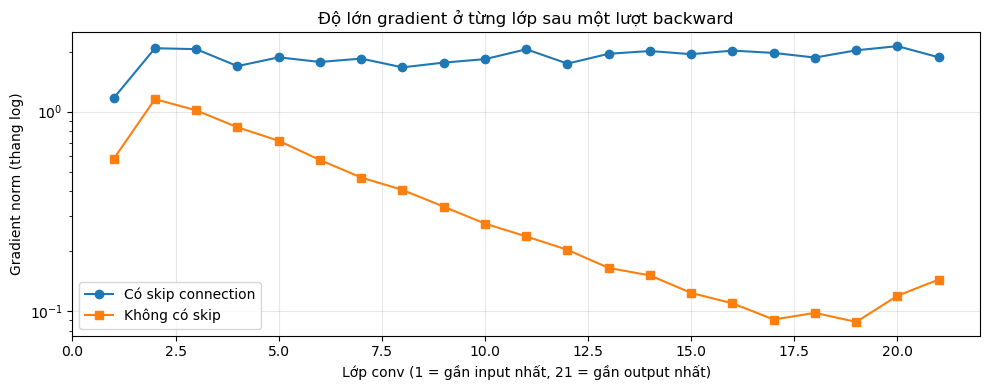

In [47]:
# Kiểm tra gradient chảy qua skip connection: một lượt backward trên dữ liệu giả
# So sánh 2 mạng sâu giống hệt nhau (1 lớp conv đầu + 10 ResidualBlock = 21 lớp conv), chỉ khác: có / không có skip
def build_stack(use_skip, n_blocks=10, channels=16):
    torch.manual_seed(0)                           # cùng trọng số khởi tạo cho cả hai mạng
    layers = [nn.Conv2d(3, channels, 3, padding=1, bias=False), nn.BatchNorm2d(channels), nn.ReLU()]
    layers += [ResidualBlock(channels, use_skip=use_skip) for _ in range(n_blocks)]
    return nn.Sequential(*layers)

def gradient_norms(model):
    torch.manual_seed(1)
    x = torch.randn(8, 3, 32, 32)                  # batch dữ liệu giả
    loss = model(x).pow(2).mean()                  # một hàm loss giả bất kỳ
    loss.backward()                                # backward: tính gradient cho mọi lớp
    # Gradient norm của trọng số mỗi lớp conv, theo thứ tự từ lớp đầu (gần input) đến lớp cuối
    return [m.weight.grad.norm().item() for m in model.modules() if isinstance(m, nn.Conv2d)]

grads_skip = gradient_norms(build_stack(use_skip=True))
grads_plain = gradient_norms(build_stack(use_skip=False))

grad_table = pd.DataFrame({
    "Lớp conv": [f"conv {i}" for i in range(1, len(grads_skip) + 1)],
    "Có skip connection": grads_skip,
    "Không có skip": grads_plain,
})
grad_table["Tỉ lệ (có / không)"] = grad_table["Có skip connection"] / grad_table["Không có skip"]
pd.set_option("display.float_format", "{:.2e}".format)
print(grad_table.to_string(index=False))
pd.reset_option("display.float_format")

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(grads_skip) + 1), grads_skip, "o-", label="Có skip connection")
plt.plot(range(1, len(grads_plain) + 1), grads_plain, "s-", label="Không có skip")
plt.yscale("log")
plt.xlabel("Lớp conv (1 = gần input nhất, 21 = gần output nhất)")
plt.ylabel("Gradient norm (thang log)")
plt.title("Độ lớn gradient ở từng lớp sau một lượt backward")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — Gradient qua skip connection:</b>
<ul>
<li><b>Kích thước đầu ra đúng như thiết kế:</b> ResidualBlock(16) giữ nguyên kích thước (4, 16, 32, 32); ResidualBlock(16→32, stride = 2) cho ra (4, 32, 16, 16) — số kênh tăng gấp đôi, ảnh thu nhỏ một nửa, và projection shortcut (Conv 1×1) đã đổi kích thước đường tắt cho khớp nên phép cộng thực hiện được; BottleneckBlock(64) giữ nguyên (4, 64, 16, 16).</li>
<li><b>Thí nghiệm:</b> hai mạng giống hệt nhau (21 lớp conv, cùng trọng số khởi tạo), chỉ khác là có hoặc không có skip connection. Sau một lượt backward trên dữ liệu giả, đo độ lớn gradient (gradient norm) ở trọng số của từng lớp conv.</li>
<li><b>Có skip connection:</b> gradient ở cả 21 lớp đều <b>mạnh và đều nhau</b>, chỉ dao động trong khoảng 1.17 – 2.13. Không có lớp nào bị thiếu tín hiệu học — chứng tỏ gradient đã chảy được qua các đường tắt đến mọi lớp.</li>
<li><b>Không có skip connection:</b> gradient <b>yếu hơn ở tất cả các lớp</b> (yếu hơn 1,8 – 23 lần) và <b>giảm dần theo độ sâu</b>: từ 1.16 ở lớp conv 2 xuống chỉ còn 0.088 ở lớp conv 19. Ở các lớp 13 – 21, gradient chỉ còn khoảng 0.09 – 0.17, yếu hơn 12 – 23 lần so với khi có skip connection. Lý do: không có đường tắt, tín hiệu học buộc phải đi qua từng lớp nối tiếp nhau, và mỗi lớp làm nó yếu đi một chút; cộng dồn qua nhiều lớp thì yếu đi rất nhiều.</li>
<li><b>Ý nghĩa:</b> lớp nào nhận gradient nhỏ thì học rất chậm. Skip connection cho gradient một con đường đi thẳng qua phép cộng mà không bị biến đổi, nên mọi lớp — dù nằm sâu đến đâu — đều nhận được tín hiệu học đủ mạnh. Đây là lý do ResNet có thể xây mạng rất sâu (hàng chục đến hàng trăm lớp) mà vẫn học được, điều mà mạng thường không có skip connection khó làm được.</li>
</ul>
</div>

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<div style="font-size:15px; font-weight:700;">3.3.2 Mini ResNet on CIFAR-10 [8 pts]</div>
ResNet-20 xây từ <code>ResidualBlock</code> ở mục 3.3.1:
<ul>
<li><b>Lớp đầu:</b> Conv 3×3 (3 → 16 kênh) → BN → ReLU</li>
<li><b>Nhóm 1:</b> 3 ResidualBlock, 16 kênh, ảnh 32×32</li>
<li><b>Nhóm 2:</b> 3 ResidualBlock, 32 kênh, ảnh 16×16 (khối đầu tiên dùng stride = 2 và projection shortcut)</li>
<li><b>Nhóm 3:</b> 3 ResidualBlock, 64 kênh, ảnh 8×8 (khối đầu tiên dùng stride = 2 và projection shortcut)</li>
<li><b>Cuối:</b> AdaptiveAvgPool(1×1) → Linear(64 → 10)</li>
</ul>
Tổng cộng 1 + 9 khối × 2 lớp conv + 1 lớp Linear = <b>20 lớp</b> có trọng số. Huấn luyện 30 epoch với <b>SGD</b> (lr = 0.1, momentum = 0.9, weight_decay = 1e-4) và <b>CosineAnnealingLR</b> (learning rate giảm dần theo đường cong cosine từ 0.1 về gần 0 sau 30 epoch), dùng cùng dữ liệu (train/validation/test và augmentation) như CustomCNN để so sánh công bằng.
</div>

In [50]:
# 3.3.2 ResNet-20 cho CIFAR-10
class ResNet20(nn.Module):
    def __init__(self, num_classes=10, blocks_per_stage=3):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)
        self.stage1 = self._make_stage(16, 16, blocks_per_stage, stride=1)   # 32×32
        self.stage2 = self._make_stage(16, 32, blocks_per_stage, stride=2)   # 16×16
        self.stage3 = self._make_stage(32, 64, blocks_per_stage, stride=2)   # 8×8
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, num_classes)

    @staticmethod
    def _make_stage(in_channels, out_channels, n_blocks, stride):
        # Khối đầu của mỗi nhóm có thể đổi số kênh / kích thước ảnh → ResidualBlock tự dùng projection shortcut
        blocks = [ResidualBlock(in_channels, out_channels, stride=stride)]
        blocks += [ResidualBlock(out_channels, out_channels) for _ in range(n_blocks - 1)]
        return nn.Sequential(*blocks)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.stage3(self.stage2(self.stage1(x)))
        return self.fc(torch.flatten(self.pool(x), 1))


resnet = ResNet20().to(device)
n_conv = sum(isinstance(m, nn.Conv2d) and m.kernel_size == (3, 3) for m in resnet.modules())
n_linear = sum(isinstance(m, nn.Linear) for m in resnet.modules())
print(f"Số lớp conv 3×3: {n_conv} + lớp Linear: {n_linear} = {n_conv + n_linear} lớp")
print(f"Tổng số tham số huấn luyện được: {count_params(resnet):,}")

with torch.no_grad():
    resnet.eval()
    print("Kiểm tra forward pass:", tuple(resnet(torch.randn(4, 3, 32, 32, device=device)).shape))

Số lớp conv 3×3: 19 + lớp Linear: 1 = 20 lớp
Tổng số tham số huấn luyện được: 272,474
Kiểm tra forward pass: (4, 10)


In [51]:
# Huấn luyện ResNet-20: 30 epoch, SGD (lr=0.1, momentum=0.9, weight_decay=1e-4), CosineAnnealingLR
torch.manual_seed(42)
resnet = ResNet20().to(device)
optimizer_res = torch.optim.SGD(resnet.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
scheduler_res = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_res, T_max=30)

history_res, time_res = fit(resnet, optimizer_res, scheduler_res, epochs=30, name="ResNet-20")

test_loss_res, test_acc_res = run_epoch(resnet, test_loader)
print(f"\nThời gian huấn luyện: {time_res / 60:.1f} phút")
print(f"Test loss: {test_loss_res:.4f} | Test accuracy: {test_acc_res:.4f}")

torch.save(resnet.state_dict(), "resnet20.pt")
with open("resnet20_history.json", "w") as f:
    json.dump({"history": history_res, "time": time_res, "test_acc": test_acc_res, "test_loss": test_loss_res}, f)
print("Đã lưu: resnet20.pt, resnet20_history.json")

[ResNet-20] Epoch  1/30 | lr=1e-01 | train loss 1.7240, acc 0.3532 | val loss 1.7177, acc 0.3908 |     14s
[ResNet-20] Epoch  2/30 | lr=1e-01 | train loss 1.2491, acc 0.5455 | val loss 1.3032, acc 0.5692 |     29s
[ResNet-20] Epoch  3/30 | lr=1e-01 | train loss 0.9991, acc 0.6423 | val loss 1.2140, acc 0.5934 |     46s
[ResNet-20] Epoch  4/30 | lr=1e-01 | train loss 0.8473, acc 0.7028 | val loss 0.9160, acc 0.6954 |     63s
[ResNet-20] Epoch  5/30 | lr=1e-01 | train loss 0.7444, acc 0.7393 | val loss 0.7434, acc 0.7426 |     78s
[ResNet-20] Epoch  6/30 | lr=9e-02 | train loss 0.6787, acc 0.7654 | val loss 0.7903, acc 0.7380 |     96s
[ResNet-20] Epoch  7/30 | lr=9e-02 | train loss 0.6244, acc 0.7838 | val loss 0.6520, acc 0.7780 |    114s
[ResNet-20] Epoch  8/30 | lr=9e-02 | train loss 0.5861, acc 0.7972 | val loss 0.6776, acc 0.7800 |    132s
[ResNet-20] Epoch  9/30 | lr=8e-02 | train loss 0.5533, acc 0.8079 | val loss 0.6478, acc 0.7796 |    150s
[ResNet-20] Epoch 10/30 | lr=8e-02 | 

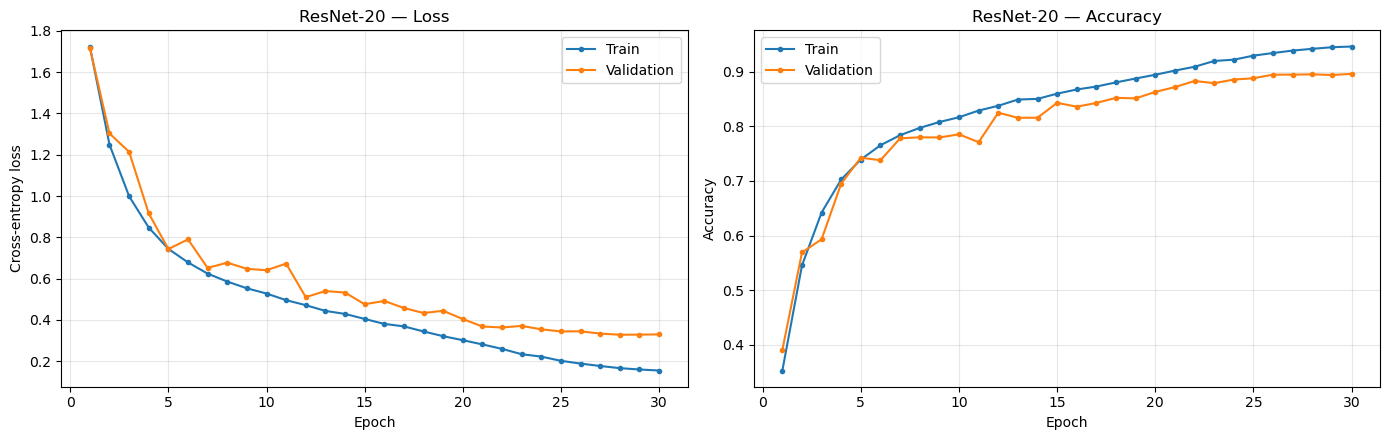

In [52]:
# Đường loss và accuracy của train/validation
plot_history(history_res, "ResNet-20")

In [53]:
# So sánh ResNet-20 với CustomCNN (mục 3.2): accuracy, số tham số, thời gian huấn luyện
compare_models = pd.DataFrame({
    "Mô hình": ["CustomCNN (3.2)", "ResNet-20 (3.3)"],
    "Số tham số": [count_params(cnn), count_params(resnet)],
    "Thời gian huấn luyện (phút)": [time_cnn / 60, time_res / 60],
    "Train acc (epoch 30)": [history_cnn["train_acc"][-1], history_res["train_acc"][-1]],
    "Val acc (epoch 30)": [history_cnn["val_acc"][-1], history_res["val_acc"][-1]],
    "Test accuracy": [test_acc_cnn, test_acc_res],
    "Test loss": [test_loss_cnn, test_loss_res],
}).round(4)
compare_models

,Mô hình,Số tham số,Thời gian huấn luyện (phút),Train acc (epoch 30),Val acc (epoch 30),Test accuracy,Test loss
0,CustomCNN (3.2),175658,6.1631,0.8163,0.8166,0.8197,0.5238
1,ResNet-20 (3.3),272474,8.7573,0.9460,0.8960,0.8930,0.3542


<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — ResNet-20 so với CustomCNN:</b>
<ul>
<li><b>Độ chính xác:</b> ResNet-20 đạt <b>test accuracy = 89,30%</b>, cao hơn CustomCNN (81,97%) <b>7,3 điểm phần trăm</b>. Nói cách khác, trên 10.000 ảnh test, số ảnh đoán sai giảm từ khoảng 1.800 xuống khoảng 1.070 — <b>ít hơn khoảng 40%</b>. Test loss cũng giảm từ 0.524 xuống 0.354.</li>
<li><b>Số tham số:</b> ResNet-20 có 272.474 tham số, nhiều hơn CustomCNN (175.658) khoảng 55%. Nhưng ResNet-20 sâu hơn rất nhiều: <b>20 lớp</b> có trọng số so với 7 lớp của CustomCNN (5 conv + 2 Linear). ResNet-20 dùng nhiều lớp "mỏng" (16 – 64 kênh) thay vì ít lớp "dày", nên dù sâu gần gấp 3 mà số tham số chỉ tăng khoảng 1,5 lần.</li>
<li><b>Thời gian huấn luyện:</b> 8,8 phút so với 6,2 phút — lâu hơn khoảng 42%, vì mạng có nhiều lớp hơn và ảnh được xử lý ở độ phân giải đầy đủ 32×32 qua 7 lớp conv đầu (nhóm đầu và lớp conv đầu tiên). Đổi thêm khoảng 2,6 phút để giảm khoảng 40% số ảnh đoán sai là rất đáng.</li>
<li><b>Vì sao ResNet-20 tốt hơn:</b> mạng sâu hơn học được những đặc điểm phức tạp hơn của ảnh (từ cạnh, góc → hình dạng → bộ phận → cả vật thể). Như đã thấy ở mục 3.3.1, nhờ skip connection mà gradient vẫn đủ mạnh ở mọi lớp, nên mạng 20 lớp này vẫn học tốt. Lưu ý: hai mô hình còn khác nhau ở cách học (CustomCNN dùng Adam + StepLR; ResNet-20 dùng SGD + momentum + weight_decay + CosineAnnealingLR theo yêu cầu của đề), nên một phần khác biệt có thể đến từ cách học chứ không hoàn toàn do kiến trúc.</li>
<li><b>Diễn biến khi học:</b> với CosineAnnealingLR, learning rate giảm từ từ, liên tục (0.1 → gần 0) thay vì giảm đột ngột như StepLR. Ở các epoch đầu, lr = 0.1 khá lớn nên validation accuracy còn lên xuống (ví dụ epoch 10 đạt 78,5% nhưng epoch 11 giảm còn 77,1%). Khi lr nhỏ dần, mô hình tiến bộ đều và ổn định; giai đoạn epoch 20 – 26 tăng mạnh nhất cuối quá trình (từ 86,3% lên 89,5%).</li>
<li><b>Overfitting:</b> khác với CustomCNN, ResNet-20 có dấu hiệu <b>học vẹt nhẹ</b>: ở epoch 30, train accuracy là 94,6% nhưng validation chỉ 89,6% (chênh 5 điểm); train loss 0.155 so với validation loss 0.330. Khoảng cách này bắt đầu xuất hiện từ khoảng epoch 7 và lớn dần. Tuy vậy, validation accuracy vẫn tiếp tục tăng đến cuối và không bị tụt, nên mức học vẹt chưa gây hại. Lý do: ResNet-20 lớn và sâu hơn nên có khả năng ghi nhớ dữ liệu train tốt hơn CustomCNN.</li>
</ul>
</div>

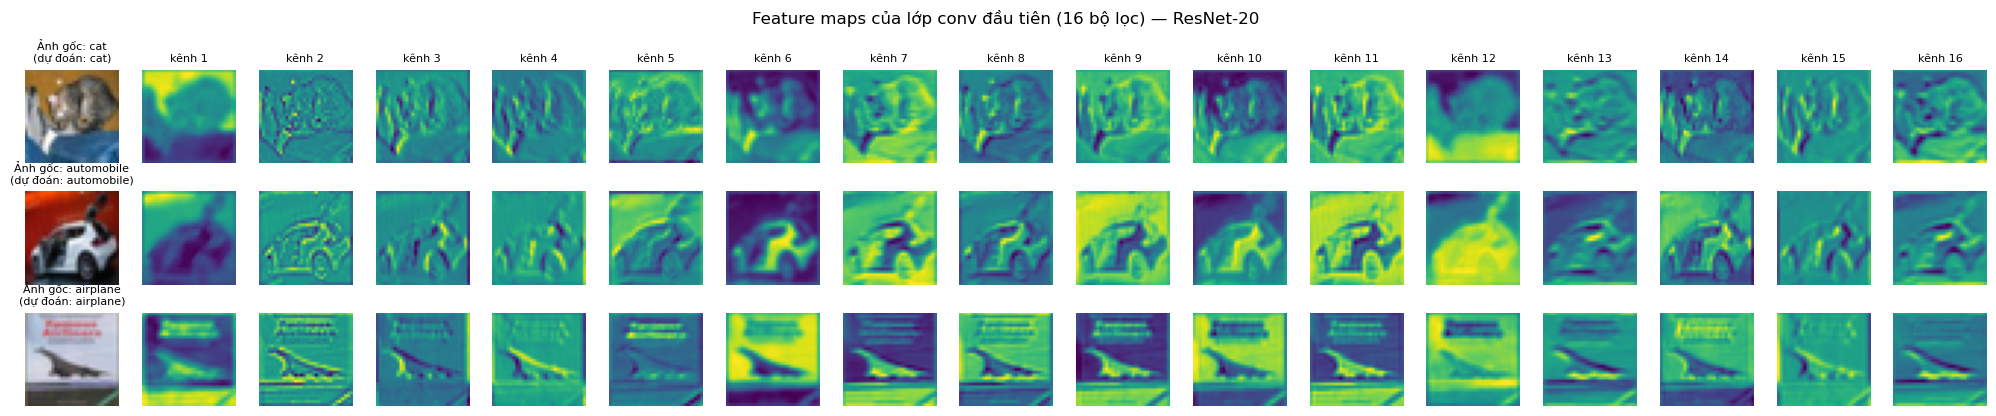

In [54]:
# Feature map của lớp conv đầu tiên (conv1: 3 → 16 kênh) cho 3 ảnh test thuộc 3 loại khác nhau
mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR_STD).view(3, 1, 1)

chosen_classes = ["cat", "automobile", "airplane"]
indices = [next(i for i, t in enumerate(test_set.targets) if classes[t] == c) for c in chosen_classes]

resnet.eval()
fig, axes = plt.subplots(len(indices), 17, figsize=(20, 4.2))
for row, idx in enumerate(indices):
    img, label = test_set[idx]
    with torch.no_grad():
        fmap = resnet.conv1(img.unsqueeze(0).to(device))[0].cpu()        # (16, 32, 32)
        pred = resnet(img.unsqueeze(0).to(device)).argmax(1).item()

    axes[row, 0].imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
    axes[row, 0].set_title(f"Ảnh gốc: {classes[label]}\n(dự đoán: {classes[pred]})", fontsize=8)
    for ch in range(16):
        axes[row, ch + 1].imshow(fmap[ch].numpy(), cmap="viridis")
        if row == 0:
            axes[row, ch + 1].set_title(f"kênh {ch + 1}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Feature maps của lớp conv đầu tiên (16 bộ lọc) — ResNet-20", fontsize=12)
plt.tight_layout()
plt.show()

<div style="font-family:'Segoe UI', Arial, sans-serif; font-size:15px; line-height:1.6;">
<b>Nhận xét — Feature maps của lớp conv đầu tiên:</b>
<ul>
<li><b>Mỗi ô là một "bộ lọc" khác nhau:</b> lớp conv đầu tiên của ResNet-20 có 16 bộ lọc 3×3, mỗi bộ lọc quét khắp ảnh và cho ra một bản đồ cho biết chỗ nào trong ảnh có đặc điểm mà bộ lọc đó "tìm kiếm". Màu vàng = phản ứng mạnh, màu tím đậm = phản ứng yếu.</li>
<li><b>Các bộ lọc học được những việc khác nhau:</b>
<ul>
<li>Một số bộ lọc <b>tìm cạnh và đường viền</b> — ví dụ kênh 2 cho ra hình giống bản vẽ phác các đường viền của chiếc xe và con mèo; nhiều kênh khác (như kênh 3, 4, 14) làm nổi các cạnh theo một hướng nhất định, giống hiệu ứng ảnh chạm nổi.</li>
<li>Một số bộ lọc <b>phản ứng với vùng màu hoặc độ sáng</b> — ví dụ kênh 1, 6, 12 cho ra các mảng sáng/tối lớn, mờ, không có chi tiết cạnh, tức là chúng phân biệt vật thể với nền dựa trên màu sắc và độ sáng.</li>
</ul></li>
<li><b>Lớp đầu chỉ thấy đặc điểm đơn giản:</b> ở lớp đầu tiên, các bản đồ vẫn giữ rõ hình dạng của ảnh gốc (vẫn nhận ra con mèo, chiếc xe, chiếc máy bay). Lớp này chưa "hiểu" đó là con mèo hay chiếc xe — nó chỉ tách ảnh thành các thành phần cơ bản như cạnh, màu, độ sáng. Các lớp sâu hơn sẽ ghép những thành phần này lại thành hình dạng, bộ phận, rồi cả vật thể, và cuối cùng mô hình đoán đúng cả 3 ảnh (cat, automobile, airplane).</li>
<li><b>Các bộ lọc này do mô hình tự học:</b> không ai lập trình sẵn "hãy tìm cạnh" — mô hình tự tìm ra rằng cạnh, màu sắc và độ sáng là những đặc điểm hữu ích để phân loại ảnh, chỉ bằng cách học từ 45.000 ảnh train.</li>
</ul>
</div>